# 03 · Random Forest, paso a paso

**Proyecto:** Salud mental en el sector tecnológico · De una encuesta larga a 7 preguntas
**Autor:** Hugo Nascimento · Proyecto final Data Analytics · IT Academy (Barcelona Activa)

En este notebook entreno un Random Forest de forma **simple y lineal**, en cinco pasos:

1. **Preprocesado:** pasar todas las variables a números.
    - Poner a las columnas un nombre que se entienda.
    - Variables realmente numéricas (solo la edad) → `StandardScaler` (z-score).
    - Variables ordinales → 0, 1, 2, 3… (y borro la columna original de la que sale la escala).
    - Variables binarias → 1 / 0.
    - Variables categóricas → `get_dummies` con `drop_first=True`.
    - Valores vacíos tratados de forma explícita (ningún vacío llega al modelo).
2. **Train / test:** separar 70 % para entrenar y 30 % para comprobar.
3. **Fit:** entrenar el modelo.
4. **Predict:** predecir con las personas que el modelo no ha visto.
5. **Evaluar:** matriz de confusión, AUC (curva ROC) y *score* (accuracy, precisión, recall, F1).

**Mi pregunta:** ¿Qué pesa más para que un profesional tech hable de su salud mental en el trabajo, y cómo puede saberlo una empresa sin ser invasiva?

El modelo central es el **19** (¿hablaría con su supervisor?): sus variables más importantes dicen dónde puede actuar la empresa. El **33** (¿tiene un trastorno?) lo uso para contrastar: ¿pesan las mismas cosas para tenerlo que para hablarlo? El **49** (¿le interfiere en el trabajo?) da contexto.

| Papel | Pregunta (target) | Qué predice el modelo |
|---|---|---|
| **Central** | 19 · ¿Te sentirías cómodo hablándolo con tu supervisor? | Sí / No (sin los «Quizá») |
| Contraste | 33 · ¿Tienes actualmente un trastorno de salud mental? | Sí / No |
| Contexto | 49 · Sin tratamiento, ¿con qué frecuencia interfiere en tu trabajo? | A menudo / no a menudo (nunca, rara vez o a veces) |

**Tipo de problema:** es **aprendizaje supervisado de clasificación**. *Supervisado* porque cada persona ya tiene la respuesta (la etiqueta) y el modelo aprende de ella. *Clasificación* porque la respuesta es una categoría (sí / no), no un número. Por eso evalúo con matriz de confusión, accuracy y AUC (el R² es para regresión, cuando se predice un número).

**Las decisiones principales que he tomado** (las explico en cada paso):

1. **Target 19:** solo «Sí» y «No»; quito «Quizá».
2. **Target 49:** «A menudo» frente al resto (nunca, rara vez o a veces).
3. **Pregunta 48:** fuera de todos los modelos, porque es casi igual que la 49.
4. **Numéricas:** solo la edad. Las notas de 0 a 10 y de 1 a 5 son ordinales, sin escalar.
5. **Categóricas:** escritas en una lista, una por una.
6. **Vacíos:** tratados de forma explícita (edad → mediana de su zona y género; ordinales y binarias → −1; categóricas → «Sin respuesta»).
7. **Un bloque por modelo**, con sus propias variables (`modelo_19`, `y_pred_33`…), sin bucle.
8. **Evaluación:** en cada modelo decido qué error es peor (falso positivo o falso negativo) y lo marco en rojo en la matriz de confusión.
9. **Destilar la encuesta:** compruebo que la 19 es el mejor objetivo y que con 7 preguntas sin datos de salud se acierta casi igual que con todas (sección final).

### Solo si ejecutas el notebook en Google Colab
La primera celda conecta con Google Drive. Fuera de Colab no hace nada.

In [1]:
import os, sys                                          # os: carpetas; sys: saber dónde se ejecuta
if "google.colab" in sys.modules:                       # si estoy en Google Colab...
    from google.colab import drive                      # ...importo la conexión con Drive
    drive.mount("/content/drive")                       # monto mi Google Drive
    os.chdir("/content/drive/MyDrive/SPRINT13_PROYECTO_FINAL_HUGO_NASCIMENTO/02_notebooks")   # me sitúo en la carpeta de notebooks

## 0. Librerías y datos

Cargo las librerías y leo los datos de la base SQLite que creé en el notebook 01 (limpieza). Me quedo con los **empleados por cuenta ajena de 2017 a 2019** (los autónomos no responden las preguntas sobre la empresa, y 2016 y 2014 no tienen las mismas preguntas).

In [2]:
import sqlite3                                          # para leer la base de datos SQLite
from pathlib import Path                                # para escribir rutas de archivos

import numpy as np                                      # cálculo numérico
import pandas as pd                                     # tablas (DataFrames)
import matplotlib.pyplot as plt                         # gráficos

from sklearn.preprocessing import StandardScaler        # escalado z-score de las variables numéricas
from sklearn.model_selection import train_test_split    # separar entrenamiento y prueba
from sklearn.ensemble import RandomForestClassifier     # el modelo: Random Forest de clasificación
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,   # matriz de confusión y su dibujo
                             classification_report, accuracy_score,     # el "score": precisión, recall, F1, accuracy
                             roc_auc_score, roc_curve, RocCurveDisplay) # AUC y curva ROC
from sklearn.inspection import permutation_importance  # importancia de cada variable
from sklearn.metrics import recall_score                # recall de una clase concreta

BASE = Path.cwd().parent                                # carpeta principal del proyecto
RUTA_SQLITE = BASE / "01_datos" / "procesados" / "salud_mental_tech.db"   # la base de datos
RUTA_FIGURAS = BASE / "04_figuras"                      # aquí guardo los gráficos
SEMILLA = 42                                            # semilla: para que el resultado sea siempre el mismo
pd.set_option("display.max_columns", 60)                # que se vean todas las columnas al mostrar tablas

In [3]:
# Leo las personas (una fila por persona) y sus respuestas (una fila por persona y pregunta)
with sqlite3.connect(RUTA_SQLITE) as con:                                   # abro la base de datos
    personas = pd.read_sql("""
        SELECT pe.persona_id, e.anio, pe.edad, pe.genero, pe.empresa_tech, pe.tamano_id, pe.pais_iso3, pa.region
        FROM personas pe
        JOIN encuestas e ON e.encuesta_id = pe.encuesta_id
        LEFT JOIN paises pa ON pa.pais_iso3 = pe.pais_iso3
        WHERE e.anio BETWEEN 2017 AND 2019 AND pe.autonomo = 0""", con)   # empleados de 2017 a 2019
    respuestas = pd.read_sql("""
        SELECT r.persona_id, r.pregunta_id, r.respuesta
        FROM respuestas r
        JOIN personas pe ON pe.persona_id = r.persona_id
        JOIN encuestas e ON e.encuesta_id = pe.encuesta_id
        WHERE e.anio BETWEEN 2017 AND 2019 AND pe.autonomo = 0""", con)   # sus respuestas

print("Personas:", len(personas))                                          # 1.308 empleados

Personas: 1308


## 1. Preprocesado

### 1.1 Una tabla con una fila por persona y un nombre claro en cada columna

Paso las respuestas a formato ancho (una columna por pregunta) y pongo a cada columna un **nombre que se entienda**, con el número de la pregunta delante para poder buscarla en el catálogo. Así no tengo que recordar qué es la pregunta 65: la columna se llama `p65_importancia_salud_mental`.

Parto de 51 variables: las preguntas de 2017-2019 que responde al menos el 50 % de las personas y que no son texto libre y quito una, la 48 (ver el recuadro). Quedan **50 variables**.

> **Decisión: quito la pregunta 48 de todos los modelos.**
> La 48 («con tratamiento, ¿con qué frecuencia interfiere en tu trabajo?») y la 49 («sin tratamiento, ¿con qué frecuencia…?») son **casi la misma pregunta**: solo cambia «con» o «sin» tratamiento. Me quedo con la 49, porque es una de mis variables objetivo, y la 48 no entra en ningún modelo.

In [4]:
# Nombre claro para cada pregunta de la encuesta que uso (número de pregunta: nombre de la columna)
NOMBRES = {
    89: "p89_raza", 13: "p13_puesto_tecnologico", 22: "p22_tuvo_empleos_anteriores",
    10: "p10_prestaciones_salud_mental", 11: "p11_anonimato_protegido", 14: "p14_conoce_opciones_atencion",
    15: "p15_empresa_hablo_del_tema", 16: "p16_empresa_ofrece_recursos", 17: "p17_facilidad_pedir_baja",
    64: "p64_importancia_salud_fisica", 65: "p65_importancia_salud_mental",
    23: "p23_anterior_prestaciones", 24: "p24_anterior_conocia_opciones", 25: "p25_anterior_hablo_del_tema",
    26: "p26_anterior_recursos", 27: "p27_anterior_anonimato", 28: "p28_anterior_hablaria_supervisor",
    68: "p68_anterior_empresa_tech", 69: "p69_anterior_comodo_fisica_o_mental", 70: "p70_anterior_hablo_con_empleador",
    72: "p72_anterior_hablo_con_companeros", 74: "p74_anterior_companero_le_hablo",
    76: "p76_anterior_importancia_fisica", 77: "p77_anterior_importancia_mental",
    12: "p12_lo_diria_en_entrevista", 18: "p18_hablaria_con_companeros", 19: "p19_hablaria_con_supervisor",
    29: "p29_diria_salud_fisica_entrevista", 30: "p30_lo_contaria_amigos_familia", 31: "p31_mal_caso_le_frena",
    57: "p57_comodo_fisica_o_mental_companeros",
    6: "p06_antecedentes_familiares", 7: "p07_ha_buscado_tratamiento", 32: "p32_trastorno_pasado",
    33: "p33_trastorno_actual", 49: "p49_interfiere_sin_tratamiento",                # la 48 ya no está
    56: "p56_vio_mala_respuesta", 83: "p83_vio_buena_respuesta", 58: "p58_hablo_con_empleador",
    60: "p60_hablo_con_companeros", 62: "p62_companero_le_hablo", 78: "p78_se_le_identifica",
    81: "p81_reaccion_companeros_0_10", 85: "p85_nota_al_sector_1_5",
}

ancho = (respuestas[respuestas["pregunta_id"].isin(NOMBRES)]            # me quedo con las preguntas que uso (sin la 48)
         .pivot(index="persona_id", columns="pregunta_id", values="respuesta")   # una columna por pregunta
         .rename(columns=NOMBRES))                                       # les pongo el nombre claro

datos = personas.set_index("persona_id").join(ancho)                    # junto perfil + respuestas (1 fila = 1 persona)
datos = datos.rename(columns={"empresa_tech": "empresa_tecnologica",    # nombres claros también para el perfil
                              "tamano_id": "tamano_empresa", "anio": "anio_encuesta"})

# Región: me quedo con UNA sola columna de lugar (EE. UU. / Europa / Resto del mundo) y borro país y región
datos["zona"] = np.select([datos["pais_iso3"] == "USA", datos["region"] == "Europa"],   # condiciones
                          ["EE. UU.", "Europa"], "Resto del mundo")                      # valores
datos = datos.drop(columns=["pais_iso3", "region"])                     # ya no las necesito (darían la misma información)

print(datos.shape)                                                       # 1.308 filas x 50 columnas
datos.head()

(1308, 50)


,anio_encuesta,edad,genero,empresa_tecnologica,tamano_empresa,p06_antecedentes_familiares,p07_ha_buscado_tratamiento,p10_prestaciones_salud_mental,p11_anonimato_protegido,p12_lo_diria_en_entrevista,p13_puesto_tecnologico,p14_conoce_opciones_atencion,p15_empresa_hablo_del_tema,p16_empresa_ofrece_recursos,p17_facilidad_pedir_baja,p18_hablaria_con_companeros,p19_hablaria_con_supervisor,p22_tuvo_empleos_anteriores,p23_anterior_prestaciones,p24_anterior_conocia_opciones,p25_anterior_hablo_del_tema,p26_anterior_recursos,p27_anterior_anonimato,p28_anterior_hablaria_supervisor,p29_diria_salud_fisica_entrevista,p30_lo_contaria_amigos_familia,p31_mal_caso_le_frena,p32_trastorno_pasado,p33_trastorno_actual,p49_interfiere_sin_tratamiento,p56_vio_mala_respuesta,p57_comodo_fisica_o_mental_companeros,p58_hablo_con_empleador,p60_hablo_con_companeros,p62_companero_le_hablo,p64_importancia_salud_fisica,p65_importancia_salud_mental,p68_anterior_empresa_tech,p69_anterior_comodo_fisica_o_mental,p70_anterior_hablo_con_empleador,p72_anterior_hablo_con_companeros,p74_anterior_companero_le_hablo,p76_anterior_importancia_fisica,p77_anterior_importancia_mental,p78_se_le_identifica,p81_reaccion_companeros_0_10,p83_vio_buena_respuesta,p85_nota_al_sector_1_5,p89_raza,zona
persona_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2694,2017,27.0,Mujer,1,4,No,Sí,No,No lo sé,No,1,Sí,No,No lo sé,No lo sé,Sí,Sí,1,No lo sé,No aplica (no las conocía),Algunos,Algunos,"Sí, siempre","Sí, todos",Sí,Neutral,No,Posiblemente,Posiblemente,A veces,"Sí, lo viví",Igual de cómodo/a con ambas,0,1,1,6,0,0,Salud física,0,0,0,3,3,0,10,"Sí, lo viví",1,NaN,Europa
2695,2017,31.0,Hombre,1,4,No,No,Sí,No lo sé,No,1,Sí,No,No,No lo sé,Sí,Quizá,1,Algunos,Conocía algunas,Ninguno,Ninguno,No lo sé,"No, ninguno",Sí,Poco abierto/a,No,Posiblemente,Posiblemente,A veces,"Sí, lo observé",Igual de cómodo/a con ambas,0,1,1,7,2,1,Salud física,0,1,0,5,2,0,6,Quizá / no estoy seguro/a,2,NaN,Europa
2696,2017,36.0,Hombre,1,2,Sí,Sí,No lo sé,Sí,No,1,No,No lo sé,No,Difícil,Quizá,Sí,1,Algunos,No aplica (no las conocía),Ninguno,Ninguno,No lo sé,"No, ninguno",Quizá,Neutral,Sí,Sí,Sí,A veces,"Sí, lo viví",Igual de cómodo/a con ambas,1,1,0,0,1,1,Salud física,0,1,0,8,0,1,5,"Sí, lo viví",1,Blanca,EE. UU.
2697,2017,22.0,Hombre,1,6,No lo sé,Sí,Sí,Sí,No,1,Sí,No lo sé,No lo sé,Difícil,Sí,Sí,0,NaN,NaN,NaN,NaN,NaN,NaN,No,Muy abierto/a,No,No,Sí,A menudo,Quizá / no estoy seguro/a,Igual de cómodo/a con ambas,1,1,0,7,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,5,Quizá / no estoy seguro/a,2,Blanca,EE. UU.
2699,2017,30.0,Hombre,1,4,Sí,No,Sí,Sí,No,0,No,No,No lo sé,Algo fácil,Quizá,Quizá,1,"No, ninguno",Conocía algunas,Ninguno,Algunos,"Sí, siempre",Algunos de mis supervisores anteriores,Quizá,Neutral,Quizá,No,No,No aplica,"Sí, lo observé",Salud física,0,0,0,9,5,1,Salud física,0,0,0,7,3,0,4,"Sí, lo observé",2,Blanca,EE. UU.


### 1.2 Qué tipo es cada variable

Antes de transformar, clasifico las 50 variables en cuatro tipos, porque **cada tipo se pasa a números de una forma distinta**. Las cuatro listas están escritas a mano, una por una, para que se vea en qué grupo va cada variable.

| Tipo | Qué es | Cómo la paso a números | Variables |
|---|---|---|---|
| **Numérica** | Un número **continuo** (puede tener decimales con sentido) | `StandardScaler` (z-score) | solo la edad |
| **Ordinal** | Categorías o notas con un **orden** | 0, 1, 2, 3… respetando el orden, **sin escalar** | año, tamaño de empresa, notas de 0 a 10, nota de 1 a 5, facilidad para pedir la baja… |
| **Binaria** | Solo dos respuestas (sí / no) | 1 = sí, 0 = no | ¿empresa tecnológica?, ¿ha buscado tratamiento?… |
| **Categórica** | Categorías **sin orden** | `get_dummies(drop_first=True)` | género, zona, raza, preguntas con «no lo sé»… |

> **Decisión: las notas de 0 a 10 y de 1 a 5 son ordinales, no numéricas.**
> Mi regla: una variable es numérica si **un valor con decimales tiene sentido**. «Tengo 37 años y medio» tiene sentido, así que la **edad** es numérica. Pero en la encuesta nadie puede responder «la importancia es 5,5»: solo hay notas enteras con un orden. Por eso las preguntas 64, 65, 76, 77, 81 (de 0 a 10) y 85 (de 1 a 5) pasan a **ordinales** y no se escalan.

In [5]:
NUMERICAS = ["edad"]                                                     # el único número continuo (37,5 años tiene sentido)

ORDINALES = ["anio_encuesta", "tamano_empresa",                          # perfil con orden
             "p17_facilidad_pedir_baja", "p30_lo_contaria_amigos_familia",   # escalas de texto con orden
             "p49_interfiere_sin_tratamiento",                           # nunca < rara vez < a veces < a menudo
             "p64_importancia_salud_fisica", "p65_importancia_salud_mental",          # notas de 0 a 10
             "p76_anterior_importancia_fisica", "p77_anterior_importancia_mental",    # notas de 0 a 10
             "p81_reaccion_companeros_0_10",                             # nota de 0 a 10
             "p85_nota_al_sector_1_5"]                                   # nota de 1 a 5

BINARIAS = ["empresa_tecnologica", "p07_ha_buscado_tratamiento", "p13_puesto_tecnologico",
            "p22_tuvo_empleos_anteriores", "p58_hablo_con_empleador", "p60_hablo_con_companeros",
            "p62_companero_le_hablo", "p68_anterior_empresa_tech", "p70_anterior_hablo_con_empleador",
            "p72_anterior_hablo_con_companeros", "p74_anterior_companero_le_hablo", "p78_se_le_identifica"]   # sí / no

CATEGORICAS = ["genero", "zona", "p89_raza",                             # perfil sin orden
               "p06_antecedentes_familiares", "p32_trastorno_pasado", "p33_trastorno_actual",   # salud mental
               "p10_prestaciones_salud_mental", "p11_anonimato_protegido", "p14_conoce_opciones_atencion",
               "p15_empresa_hablo_del_tema", "p16_empresa_ofrece_recursos",                   # empresa actual
               "p23_anterior_prestaciones", "p24_anterior_conocia_opciones", "p25_anterior_hablo_del_tema",
               "p26_anterior_recursos", "p27_anterior_anonimato", "p28_anterior_hablaria_supervisor",
               "p69_anterior_comodo_fisica_o_mental",                                         # empresa anterior
               "p12_lo_diria_en_entrevista", "p18_hablaria_con_companeros", "p19_hablaria_con_supervisor",
               "p29_diria_salud_fisica_entrevista", "p31_mal_caso_le_frena",
               "p57_comodo_fisica_o_mental_companeros",                                       # apertura
               "p56_vio_mala_respuesta", "p83_vio_buena_respuesta"]                           # lo que ha visto

todas = NUMERICAS + ORDINALES + BINARIAS + CATEGORICAS                   # las cuatro listas juntas
print(f"Numéricas: {len(NUMERICAS)} · Ordinales: {len(ORDINALES)} · Binarias: {len(BINARIAS)} · "
      f"Categóricas: {len(CATEGORICAS)} · Total: {len(todas)}")
print("¿Falta alguna columna en las listas?", sorted(set(datos.columns) - set(todas)))   # tiene que salir []
print("¿Hay alguna repetida?", len(todas) != len(set(todas)))                            # tiene que salir False

Numéricas: 1 · Ordinales: 11 · Binarias: 12 · Categóricas: 26 · Total: 50
¿Falta alguna columna en las listas? []
¿Hay alguna repetida? False


### 1.3 Antes de transformar, guardo las tres variables objetivo (*target*)

Las tres preguntas que quiero predecir las guardo aparte, **cogiendo la columna tal cual**, con sus etiquetas en texto («Sí», «No»…), para que las predicciones se lean fácil. Lo único que hago es quedarme con las personas que tienen una respuesta clara.

> **Decisión: el target se coge tal cual de la columna.**
>
> - **Modelo 19 · ¿hablaría con su supervisor?** Me quedo **solo con quien responde «Sí» o «No»** y **quito «Quizá»**. No transformo nada: es la respuesta tal como la dio la persona. Pasan de 1.308 a **875 personas**.
> - **Modelo 33 · ¿tiene un trastorno ahora?** Igual: solo «Sí» o «No» (quito «Posiblemente» y «No lo sé»).
> - **Modelo 49 · sin tratamiento, ¿le interfiere en el trabajo?** Tiene cuatro respuestas (nunca, rara vez, a veces, a menudo). Para que sea sí / no comparo **«A menudo» frente al resto** (nunca, rara vez o a veces). Es la única agrupación que hago, y solo con personas que tienen un trastorno (quito «No aplica»).

In [6]:
# --- Modelo 19: solo "Sí" y "No" (quito "Quizá") ---
filas_19 = datos["p19_hablaria_con_supervisor"].isin(["Sí", "No"])      # True si respondió Sí o No
target_19 = datos.loc[filas_19, "p19_hablaria_con_supervisor"]           # la columna tal cual, sin transformar

# --- Modelo 33: solo "Sí" y "No" (quito "Posiblemente" y "No lo sé") ---
filas_33 = datos["p33_trastorno_actual"].isin(["Sí", "No"])             # True si respondió Sí o No
target_33 = datos.loc[filas_33, "p33_trastorno_actual"]                  # la columna tal cual, sin transformar

# --- Modelo 49: "A menudo" frente al resto (solo personas con trastorno) ---
filas_49 = datos["p49_interfiere_sin_tratamiento"] != "No aplica"       # quito a quien no tiene trastorno
target_49 = datos.loc[filas_49, "p49_interfiere_sin_tratamiento"]        # nunca / rara vez / a veces / a menudo
target_49 = target_49.where(target_49 == "A menudo", "No a menudo")      # si no es "A menudo", pasa a "No a menudo"

print("19 →", len(target_19), "personas ·", target_19.value_counts().to_dict())   # cuántos de cada clase
print("33 →", len(target_33), "personas ·", target_33.value_counts().to_dict())
print("49 →", len(target_49), "personas ·", target_49.value_counts().to_dict())

19 → 875 personas · {'Sí': 504, 'No': 371}
33 → 945 personas · {'Sí': 573, 'No': 372}
49 → 891 personas · {'A menudo': 555, 'No a menudo': 336}


**¿Las clases están equilibradas?** Se trata de mirar, dentro de cada target, cuántas personas hay de cada respuesta. En los tres casos la clase más pequeña está alrededor del 40 % (un desequilibrio fuerte sería un 95 % / 5 %). Por eso no hace falta equilibrar las clases, pero lo vigilo en la matriz de confusión: si el modelo acierta mucho más una clase que la otra, se verá ahí.

### 1.4 Valores vacíos (`NaN`): los trato antes de transformar

Antes de pasar nada a números miro **cuántos vacíos hay en cada columna**, para decidir qué hago con ellos y que **ningún vacío llegue al modelo**.

> **Decisión: los vacíos se tratan de forma explícita, columna a columna.**
>
> - **Edad:** solo falta en 1 persona → le pongo la **mediana de las personas más parecidas a ella: su misma zona y su mismo género**. Es más correcto que la mediana de todo el mundo, porque la edad cambia según el lugar y el grupo.
> - **Ordinales y binarias:** el vacío (o «No lo sé», «No aplica») pasa a ser **−1 = sin respuesta**. Es un valor que no está en la escala (que empieza en 0), así el modelo puede separar a quien no respondió. Casi todos son las 179 personas que **no tuvieron un empleo anterior**, y por eso no responden las preguntas sobre la empresa anterior.
> - **Categóricas:** el vacío pasa a ser la categoría **«Sin respuesta»**.

In [7]:
vacios = datos.isna().sum()                                              # cuántos vacíos tiene cada columna
vacios[vacios > 0].sort_values(ascending=False).to_frame("vacíos")      # solo las columnas que tienen alguno

,vacíos
p89_raza,409
p31_mal_caso_le_frena,266
p74_anterior_companero_le_hablo,183
p72_anterior_hablo_con_companeros,182
p70_anterior_hablo_con_empleador,179
p69_anterior_comodo_fisica_o_mental,179
p23_anterior_prestaciones,179
p24_anterior_conocia_opciones,179
p28_anterior_hablaria_supervisor,179
p25_anterior_hablo_del_tema,179


In [8]:
tabla_preprocesada = datos.copy()                                        # la tabla que voy a pasar toda a números (copia: datos no se toca)

sin_edad = tabla_preprocesada["edad"].isna()                            # True para la persona que no dio su edad
print("Persona sin edad:", tabla_preprocesada.loc[sin_edad, ["zona", "genero"]].to_dict("index"))   # su zona y su género

mediana_grupo = tabla_preprocesada.groupby(["zona", "genero"])["edad"].transform("median")   # mediana de edad de cada zona + género
tabla_preprocesada["edad"] = tabla_preprocesada["edad"].fillna(mediana_grupo)   # recibe la mediana de las personas más parecidas
print("Edad que recibe (mediana de su zona y su género):", tabla_preprocesada.loc[sin_edad, "edad"].tolist())

Persona sin edad: {3981: {'zona': 'EE. UU.', 'genero': 'Hombre'}}
Edad que recibe (mediana de su zona y su género): [35.0]


### 1.5 Variable numérica (edad) → `StandardScaler` (z-score)

El z-score resta la media y divide por la desviación típica: la edad queda con media 0 y desviación 1.

**Un detalle:** en un Random Forest el escalado **no cambia el resultado**, porque cada árbol solo pregunta «¿es mayor o menor que…?», y el orden de las edades no cambia al escalar. Lo hago porque así los datos quedan listos para cualquier otro modelo (por ejemplo, una regresión, que sí lo necesita).

In [9]:
escalador = StandardScaler()                                             # creo el escalador z-score
tabla_preprocesada[["edad"]] = escalador.fit_transform(tabla_preprocesada[["edad"]])              # calcula media y desviación y transforma

tabla_preprocesada[["edad"]].describe().loc[["mean", "std"]].round(2)                # comprobación: media 0 y desviación 1

,edad
mean,-0.0
std,1.0


### 1.6 Variables ordinales → 0, 1, 2, 3… (sin escalar)

Las ordinales tienen un orden (por ejemplo, el tamaño de la empresa: de 1-5 empleados a más de 1.000). Las paso a números **respetando ese orden**, empezando en 0. Así el modelo sabe que «muy fácil» está más lejos de «difícil» que «algo fácil».

- Las de texto (17, 30, 49) las traduzco con una escala escrita a mano.
- Las notas de 0 a 10 ya son números en orden: solo las paso de texto («7») a número (7).
- La nota de 1 a 5 la paso a 0-4 (le resto 1) para que todas empiecen en 0.
- Lo que no está en la escala («No lo sé», «No aplica» o vacío) pasa a **−1 = sin respuesta**.

Cada ordinal sustituye a su columna de texto: **la columna original desaparece** (la sobrescribo).

In [10]:
NOTA_0_10 = {str(n): n for n in range(11)}                               # "0" → 0, "1" → 1, ..., "10" → 10
ESCALAS = {
    "anio_encuesta": {2017: 0, 2018: 1, 2019: 2},                                         # años: 0, 1, 2
    "tamano_empresa": {1: 0, 2: 1, 3: 2, 4: 3, 5: 4, 6: 5},                                # de 1-5 empleados (0) a más de 1.000 (5)
    "p17_facilidad_pedir_baja": {"Difícil": 0, "Algo difícil": 1, "Ni fácil ni difícil": 2,
                                 "Algo fácil": 3, "Muy fácil": 4},                         # "No lo sé" → -1
    "p30_lo_contaria_amigos_familia": {"Nada abierto/a": 0, "Poco abierto/a": 1, "Neutral": 2,
                                       "Algo abierto/a": 3, "Muy abierto/a": 4},
    "p49_interfiere_sin_tratamiento": {"Nunca": 0, "Rara vez": 1, "A veces": 2, "A menudo": 3},   # "No aplica" → -1
    "p64_importancia_salud_fisica": NOTA_0_10, "p65_importancia_salud_mental": NOTA_0_10,         # notas de 0 a 10
    "p76_anterior_importancia_fisica": NOTA_0_10, "p77_anterior_importancia_mental": NOTA_0_10,
    "p81_reaccion_companeros_0_10": NOTA_0_10,
    "p85_nota_al_sector_1_5": {"1": 0, "2": 1, "3": 2, "4": 3, "5": 4},                          # de 1-5 a 0-4
}
for col, escala in ESCALAS.items():
    sin_escala = tabla_preprocesada[col].notna() & ~tabla_preprocesada[col].isin(list(escala))    # respuestas que no están en la escala
    print(f"{col}: {tabla_preprocesada[col].isna().sum()} vacíos y {sin_escala.sum()} fuera de la escala "
          f"{sorted(tabla_preprocesada.loc[sin_escala, col].unique().tolist())} → -1")   # digo cuántos pasan a -1 y cuáles
    tabla_preprocesada[col] = tabla_preprocesada[col].map(escala).fillna(-1).astype(int)          # texto → número; lo que no está en la escala → -1

tabla_preprocesada[ORDINALES].head()

anio_encuesta: 0 vacíos y 0 fuera de la escala [] → -1
tamano_empresa: 0 vacíos y 0 fuera de la escala [] → -1
p17_facilidad_pedir_baja: 0 vacíos y 229 fuera de la escala ['No lo sé'] → -1
p30_lo_contaria_amigos_familia: 0 vacíos y 0 fuera de la escala [] → -1
p49_interfiere_sin_tratamiento: 0 vacíos y 417 fuera de la escala ['No aplica'] → -1
p64_importancia_salud_fisica: 0 vacíos y 0 fuera de la escala [] → -1
p65_importancia_salud_mental: 0 vacíos y 0 fuera de la escala [] → -1
p76_anterior_importancia_fisica: 179 vacíos y 0 fuera de la escala [] → -1
p77_anterior_importancia_mental: 179 vacíos y 0 fuera de la escala [] → -1
p81_reaccion_companeros_0_10: 0 vacíos y 0 fuera de la escala [] → -1
p85_nota_al_sector_1_5: 0 vacíos y 0 fuera de la escala [] → -1


,anio_encuesta,tamano_empresa,p17_facilidad_pedir_baja,p30_lo_contaria_amigos_familia,p49_interfiere_sin_tratamiento,p64_importancia_salud_fisica,p65_importancia_salud_mental,p76_anterior_importancia_fisica,p77_anterior_importancia_mental,p81_reaccion_companeros_0_10,p85_nota_al_sector_1_5
persona_id,,,,,,,,,,,
2694,0,3,-1,2,2,6,0,3,3,10,0
2695,0,3,-1,1,2,7,2,5,2,6,1
2696,0,1,0,2,2,0,1,8,0,5,0
2697,0,5,0,4,3,7,5,-1,-1,5,1
2699,0,3,3,2,-1,9,5,7,3,4,1


### 1.7 Variables binarias → 1 = sí, 0 = no

Las de dos respuestas pasan a 1 y 0. Algunas ya venían como «1»/«0» en la base de datos. Es lo mismo que haría `get_dummies` con `drop_first=True`, pero más fácil de leer. El vacío pasa a **−1 = sin respuesta**.

In [11]:
A_NUMERO = {"Sí": 1, "No": 0, "1": 1, "0": 0, 1: 1, 0: 0}                 # todas las formas de escribir sí / no
for col in BINARIAS:
    print(f"{col}: {tabla_preprocesada[col].isna().sum()} vacíos → -1")              # digo cuántos vacíos tiene cada una
    tabla_preprocesada[col] = tabla_preprocesada[col].map(A_NUMERO).fillna(-1).astype(int)        # "Sí" → 1, "No" → 0, vacío → -1

tabla_preprocesada[BINARIAS].head()

empresa_tecnologica: 0 vacíos → -1
p07_ha_buscado_tratamiento: 0 vacíos → -1
p13_puesto_tecnologico: 0 vacíos → -1
p22_tuvo_empleos_anteriores: 0 vacíos → -1
p58_hablo_con_empleador: 0 vacíos → -1
p60_hablo_con_companeros: 4 vacíos → -1
p62_companero_le_hablo: 6 vacíos → -1
p68_anterior_empresa_tech: 179 vacíos → -1
p70_anterior_hablo_con_empleador: 179 vacíos → -1
p72_anterior_hablo_con_companeros: 182 vacíos → -1
p74_anterior_companero_le_hablo: 183 vacíos → -1
p78_se_le_identifica: 0 vacíos → -1


,empresa_tecnologica,p07_ha_buscado_tratamiento,p13_puesto_tecnologico,p22_tuvo_empleos_anteriores,p58_hablo_con_empleador,p60_hablo_con_companeros,p62_companero_le_hablo,p68_anterior_empresa_tech,p70_anterior_hablo_con_empleador,p72_anterior_hablo_con_companeros,p74_anterior_companero_le_hablo,p78_se_le_identifica
persona_id,,,,,,,,,,,,
2694,1,1,1,1,0,1,1,0,0,0,0,0
2695,1,0,1,1,0,1,1,1,0,1,0,0
2696,1,1,1,1,1,1,0,1,0,1,0,1
2697,1,1,1,0,1,1,0,-1,-1,-1,-1,0
2699,1,0,0,1,0,0,0,1,0,0,0,0


### 1.8 Variables categóricas → `get_dummies(drop_first=True)`

Las categóricas sin orden (por ejemplo el género: hombre, mujer, no binario) se convierten en **una columna de 0/1 por categoría**.

Con `drop_first=True` quito la primera columna de cada variable, porque **sobra**: si una persona no es «mujer» ni «no binario», ya sé que es «hombre». Si la dejara, esa columna se podría calcular con las otras (multicolinealidad perfecta).

Antes, a las respuestas vacías les pongo la categoría «Sin respuesta», para que no se confundan con la categoría que quito.

In [12]:
tabla_preprocesada[CATEGORICAS] = tabla_preprocesada[CATEGORICAS].fillna("Sin respuesta")           # el vacío pasa a ser una categoría más
tabla_preprocesada = pd.get_dummies(tabla_preprocesada, columns=CATEGORICAS, drop_first=True,      # una columna 0/1 por categoría, sin la primera
                       prefix_sep="__", dtype=int)                       # "__" separa el nombre de la variable y la categoría

print("Columnas después del preprocesado:", tabla_preprocesada.shape[1])              # de 50 variables salen más columnas por las dummies
tabla_preprocesada.filter(like="genero").head()                                       # ejemplo: el género en dos columnas

Columnas después del preprocesado: 106


,genero__Mujer,genero__No binario / otra identidad,genero__No responde / no clasificable
persona_id,,,
2694,1,0,0
2695,0,0,0
2696,0,0,0
2697,0,0,0
2699,0,0,0


**Comprobación final del preprocesado:** la tabla solo tiene números y **ningún vacío**. Cada fila es una persona; cada columna, una variable (o una categoría de una variable categórica).

In [13]:
print("Tipos de columna:", tabla_preprocesada.dtypes.value_counts().to_dict())       # solo números (int y float)
print("Vacíos en toda la tabla:", int(tabla_preprocesada.isna().sum().sum()))         # tiene que salir 0

Tipos de columna: {dtype('int64'): 105, dtype('float64'): 1}
Vacíos en toda la tabla: 0


### 1.9 Variables que no pueden entrar en cada modelo (exclusión manual)

Para cada modelo quito:

1. **La propia variable objetivo** (no puedo usar la respuesta para predecir la respuesta).
2. **Las preguntas que son la misma pregunta con otras palabras**, porque le darían la respuesta al modelo. Las he revisado una a una:

| Modelo | Quito | Por qué |
|---|---|---|
| 19 · Supervisor | 18 · Hablaría con compañeros | Es la misma pregunta cambiando «supervisor» por «compañeros». |
| 33 · Trastorno actual | 32 · Trastorno en el pasado | Quien lo tiene ahora casi siempre responde que también lo tuvo antes. |
| 33 · Trastorno actual | 49 · Interferencia | Solo la responde quien tiene un trastorno: «No aplica» delataría el «No». |
| Todos | 48 · Interfiere con tratamiento | Ya no está en los datos (ver 1.1). |

**«¿Has buscado tratamiento?» (7) sí entra.** Está relacionada con tener un trastorno, pero no es lo mismo: alguien puede tener un trastorno y no haber buscado tratamiento. Si la quitara, le quitaría al modelo información real de la encuesta. Cada exclusión está justificada a mano.

**Cómo sé a qué pregunta pertenece cada columna.** Después de `get_dummies`, una pregunta puede tener varias columnas: `p33_trastorno_actual__Sí`, `p33_trastorno_actual__Sin respuesta`… El nombre de la pregunta es **lo que hay antes de `__`**. La función `pregunta_de` hace justo eso, y la uso para quitar todas las columnas de una pregunta de golpe.

In [14]:
def pregunta_de(columna):
    return columna.split("__")[0]                                        # "p33_trastorno_actual__Sí" → "p33_trastorno_actual"

print(pregunta_de("p33_trastorno_actual__Sí"))                           # ejemplo con una dummy
print(pregunta_de("edad"))                                               # si no hay "__", se queda igual

QUITAR_19 = ["p19_hablaria_con_supervisor", "p18_hablaria_con_companeros"]                           # target + misma pregunta
QUITAR_33 = ["p33_trastorno_actual", "p32_trastorno_pasado", "p49_interfiere_sin_tratamiento"]       # target + delatoras
QUITAR_49 = ["p49_interfiere_sin_tratamiento"]                                                       # solo el target

columnas_19 = [c for c in tabla_preprocesada.columns if pregunta_de(c) not in QUITAR_19]   # columnas que sí entran en el modelo 19
columnas_33 = [c for c in tabla_preprocesada.columns if pregunta_de(c) not in QUITAR_33]   # ... en el modelo 33
columnas_49 = [c for c in tabla_preprocesada.columns if pregunta_de(c) not in QUITAR_49]   # ... en el modelo 49

X_19 = tabla_preprocesada.loc[target_19.index, columnas_19]                           # personas del modelo 19 x sus columnas
X_33 = tabla_preprocesada.loc[target_33.index, columnas_33]                           # personas del modelo 33 x sus columnas
X_49 = tabla_preprocesada.loc[target_49.index, columnas_49]                           # personas del modelo 49 x sus columnas

print(f"Modelo 19: {X_19.shape[0]} personas x {X_19.shape[1]} columnas")
print(f"Modelo 33: {X_33.shape[0]} personas x {X_33.shape[1]} columnas")
print(f"Modelo 49: {X_49.shape[0]} personas x {X_49.shape[1]} columnas")

p33_trastorno_actual
edad
Modelo 19: 875 personas x 102 columnas
Modelo 33: 945 personas x 98 columnas
Modelo 49: 891 personas x 105 columnas


Así se ve la tabla de un modelo (primeras filas del modelo 19). Para guardarla en un CSV y abrirla en Excel: `X_19.join(target_19).to_csv("tabla_modelo_19.csv")`.

In [15]:
X_19.head()                                                              # primeras 5 personas del modelo 19

,anio_encuesta,edad,empresa_tecnologica,tamano_empresa,p07_ha_buscado_tratamiento,p13_puesto_tecnologico,p17_facilidad_pedir_baja,p22_tuvo_empleos_anteriores,p30_lo_contaria_amigos_familia,p49_interfiere_sin_tratamiento,p58_hablo_con_empleador,p60_hablo_con_companeros,p62_companero_le_hablo,p64_importancia_salud_fisica,p65_importancia_salud_mental,p68_anterior_empresa_tech,p70_anterior_hablo_con_empleador,p72_anterior_hablo_con_companeros,p74_anterior_companero_le_hablo,p76_anterior_importancia_fisica,p77_anterior_importancia_mental,p78_se_le_identifica,p81_reaccion_companeros_0_10,p85_nota_al_sector_1_5,genero__Mujer,genero__No binario / otra identidad,genero__No responde / no clasificable,zona__Europa,zona__Resto del mundo,p89_raza__Blanca,p89_raza__Caucasian,p89_raza__Hispana,p89_raza__Indígena americana o nativa de Alaska,p89_raza__Más de una de las anteriores,p89_raza__Negra o afroamericana,p89_raza__Prefiero no responder,p89_raza__Sin respuesta,p89_raza__White Hispanic,p06_antecedentes_familiares__No lo sé,p06_antecedentes_familiares__Sí,p32_trastorno_pasado__No lo sé,p32_trastorno_pasado__Posiblemente,p32_trastorno_pasado__Sin respuesta,p32_trastorno_pasado__Sí,p33_trastorno_actual__No lo sé,p33_trastorno_actual__Posiblemente,p33_trastorno_actual__Sí,p10_prestaciones_salud_mental__No lo sé,p10_prestaciones_salud_mental__Sin cobertura / no aplica,p10_prestaciones_salud_mental__Sí,p11_anonimato_protegido__No lo sé,p11_anonimato_protegido__Sí,p14_conoce_opciones_atencion__Sin respuesta,p14_conoce_opciones_atencion__Sí,p15_empresa_hablo_del_tema__No lo sé,p15_empresa_hablo_del_tema__Sí,p16_empresa_ofrece_recursos__No lo sé,p16_empresa_ofrece_recursos__Sí,p23_anterior_prestaciones__No lo sé,"p23_anterior_prestaciones__No, ninguno",p23_anterior_prestaciones__Sin respuesta,"p23_anterior_prestaciones__Sí, todos",p24_anterior_conocia_opciones__No aplica (no las conocía),p24_anterior_conocia_opciones__No aplica (no se ofrecían),"p24_anterior_conocia_opciones__No, me enteré después",p24_anterior_conocia_opciones__Sin respuesta,"p24_anterior_conocia_opciones__Sí, las conocía todas",p25_anterior_hablo_del_tema__Ninguno,p25_anterior_hablo_del_tema__No lo sé,p25_anterior_hablo_del_tema__Sin respuesta,"p25_anterior_hablo_del_tema__Sí, todos",p26_anterior_recursos__Ninguno,p26_anterior_recursos__Sin respuesta,"p26_anterior_recursos__Sí, todos",p27_anterior_anonimato__No,p27_anterior_anonimato__No lo sé,p27_anterior_anonimato__Sin respuesta,"p27_anterior_anonimato__Sí, siempre",p28_anterior_hablaria_supervisor__No lo sé,"p28_anterior_hablaria_supervisor__No, ninguno",p28_anterior_hablaria_supervisor__Sin respuesta,"p28_anterior_hablaria_supervisor__Sí, todos",p69_anterior_comodo_fisica_o_mental__Salud física,p69_anterior_comodo_fisica_o_mental__Salud mental,p69_anterior_comodo_fisica_o_mental__Sin respuesta,p12_lo_diria_en_entrevista__Quizá,p12_lo_diria_en_entrevista__Sí,p29_diria_salud_fisica_entrevista__Quizá,p29_diria_salud_fisica_entrevista__Sí,p31_mal_caso_le_frena__Quizá,p31_mal_caso_le_frena__Sin respuesta,p31_mal_caso_le_frena__Sí,p57_comodo_fisica_o_mental_companeros__Salud física,p57_comodo_fisica_o_mental_companeros__Salud mental,p56_vio_mala_respuesta__Quizá / no estoy seguro/a,p56_vio_mala_respuesta__Siempre he sido autónomo/a,"p56_vio_mala_respuesta__Sí, lo observé","p56_vio_mala_respuesta__Sí, lo viví",p83_vio_buena_respuesta__Quizá / no estoy seguro/a,p83_vio_buena_respuesta__Siempre he sido autónomo/a,"p83_vio_buena_respuesta__Sí, lo observé","p83_vio_buena_respuesta__Sí, lo viví"
persona_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2694,0,-0.956501,1,3,1,1,-1,1,2,2,0,1,1,6,0,0,0,0,0,3,3,0,10,0,1,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,1,0,0,1,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,1
2696,0,0.160334,1,1,1,1,0,1,2,2,1,1,0,0,1,1,0,1,0,8,0,1,5,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1,1,0,0,0,1,

## Modelo 19 · ¿Hablaría con su supervisor? — explicado línea a línea

Lo hago primero con el modelo 19, que es el central de mi presentación. Después repito **exactamente los mismos pasos** con el 33 y el 49, cada uno con sus propias variables (`X_train_33`, `y_pred_49`…), para que no se pisen.

> **Decisión: cada modelo con sus propias variables, sin bucle.**
> Cada modelo tiene los suyos (`modelo_19`, `modelo_33`, `modelo_49`), así se puede revisar cada uno por separado.

### 2. Train / test

Separo a las personas en dos grupos: el **70 %** para que el modelo aprenda (*train*) y el **30 %** que guardo aparte y el modelo **no ve nunca** al entrenar (*test*). Con el *test* compruebo si ha aprendido de verdad o solo ha memorizado.

`stratify` hace que los dos grupos tengan el mismo % de «Sí» que el total. `random_state=SEMILLA` (42) hace que la separación al azar sea **siempre la misma** cada vez que ejecuto el notebook.

In [16]:
y_19 = target_19                                                         # la respuesta: "Sí" o "No"

X_train_19, X_test_19, y_train_19, y_test_19 = train_test_split(
    X_19, y_19,
    test_size=0.3,                                                       # 30 % para el test
    random_state=SEMILLA,                                                # misma separación cada vez que lo ejecuto
    stratify=y_19)                                                       # mismo % de "Sí" en train y en test

print("Train:", X_train_19.shape[0], "personas · Test:", X_test_19.shape[0], "personas")
print("% de 'Sí' en train:", round(100 * (y_train_19 == "Sí").mean(), 1),
      "· en test:", round(100 * (y_test_19 == "Sí").mean(), 1))

Train: 612 personas · Test: 263 personas
% de 'Sí' en train: 57.7 · en test: 57.4


### 3. Fit (entrenar)

Creo el Random Forest y lo entreno con el 70 %. Los parámetros que elijo:

- `n_estimators=500`: **500 árboles**. Cada árbol aprende con una muestra distinta de personas (*bootstrap*: muestreo con reemplazo) y al final **votan**; gana la mayoría.
- `max_features="sqrt"`: en cada corte, cada árbol solo puede mirar la **raíz cuadrada** del número de columnas, elegidas al azar. Así los árboles son distintos entre sí y el voto es más fiable.
- `min_samples_leaf=5`: cada hoja final tiene al menos **5 personas**. Evita que un árbol memorice casos sueltos (sobreajuste).
- `random_state=42`: para que el resultado sea siempre el mismo.
- Cada corte se decide con la **impureza de Gini**: el árbol elige la pregunta que deja los grupos más «puros» (más sí por un lado y más no por el otro).

In [17]:
modelo_19 = RandomForestClassifier(
    n_estimators=500,                                                    # 500 árboles que votan
    max_features="sqrt",                                                 # en cada corte, raíz cuadrada de las columnas al azar
    min_samples_leaf=5,                                                  # mínimo 5 personas en cada hoja
    random_state=SEMILLA,                                                # resultado repetible
    n_jobs=-1)                                                           # usa todos los procesadores (más rápido)

modelo_19.fit(X_train_19, y_train_19)                                    # ENTRENAR: aprende con el 70 %
print("Clases que ha aprendido:", list(modelo_19.classes_))

Clases que ha aprendido: ['No', 'Sí']


### 4. Predict (predecir)

Pido al modelo que prediga el 30 % de *test*. Las predicciones salen como «Sí» o «No», igual que las respuestas reales, para poder compararlas fácilmente.

In [18]:
y_pred_19 = modelo_19.predict(X_test_19)                                 # PREDECIR: "Sí" o "No" para cada persona del test

comparacion = pd.DataFrame({"respuesta real": y_test_19.values, "predicción": y_pred_19}).head(10)   # primeras 10 personas
comparacion["¿acierta?"] = np.where(comparacion["respuesta real"] == comparacion["predicción"], "sí", "no")
comparacion

,respuesta real,predicción,¿acierta?
0,Sí,Sí,sí
1,Sí,Sí,sí
2,Sí,No,no
3,Sí,No,no
4,Sí,Sí,sí
5,Sí,Sí,sí
6,No,No,sí
7,Sí,Sí,sí
8,Sí,Sí,sí
9,Sí,Sí,sí


### 5. Evaluar

#### 5.1 Matriz de confusión

Cruza la **respuesta real** (filas) con la **predicción** (columnas). En la diagonal están los aciertos; fuera, los errores:

| | El modelo dice **Sí** | El modelo dice **No** |
|---|---|---|
| **Es Sí** | Verdadero positivo ✔ | **Falso negativo** ✘ (se le escapa un «sí») |
| **Es No** | **Falso positivo** ✘ (falsa alarma) | Verdadero negativo ✔ |

> **Decisión: decidir qué error es peor en cada modelo.**
> Las dos casillas de error no pesan lo mismo. Hay que pensar **qué pasaría en la vida real** con cada error.
>
> **En el modelo 19, el error peor es el falso positivo:** el modelo dice que la persona **sí** hablaría con su supervisor, pero en realidad **no** lo haría. La empresa pensaría «aquí la gente habla, todo va bien», y esa persona seguiría callando su problema. Por eso en este modelo me fijo sobre todo en el **recall del «No»**: de las personas que **no** hablarían, ¿cuántas detecta el modelo? En la matriz lo marco con un recuadro rojo.

Falsos positivos (no hablaría, pero el modelo dice que sí): 25
Falsos negativos (sí hablaría, pero el modelo dice que no): 21


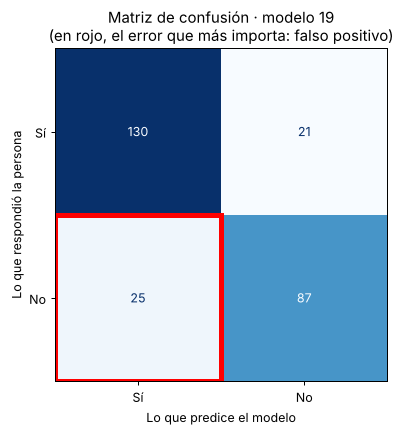

In [19]:
etiquetas_19 = ["Sí", "No"]                                              # orden: primero la clase positiva
matriz_19 = confusion_matrix(y_test_19, y_pred_19, labels=etiquetas_19)  # cuenta aciertos y errores
ConfusionMatrixDisplay(matriz_19, display_labels=etiquetas_19).plot(cmap="Blues", colorbar=False)   # la dibujo
plt.gca().add_patch(plt.Rectangle((-0.5, 0.5), 1, 1, fill=False, edgecolor="red", linewidth=4))   # recuadro: fila "No", columna "Sí"
plt.title("Matriz de confusión · modelo 19\n(en rojo, el error que más importa: falso positivo)")
plt.xlabel("Lo que predice el modelo"); plt.ylabel("Lo que respondió la persona")
plt.show()

print("Falsos positivos (no hablaría, pero el modelo dice que sí):", matriz_19[1, 0])
print("Falsos negativos (sí hablaría, pero el modelo dice que no):", matriz_19[0, 1])

#### 5.2 *Score*: accuracy, error, precisión, recall y F1

In [20]:
accuracy_19 = accuracy_score(y_test_19, y_pred_19)                       # % de aciertos sobre el total
print(f"Accuracy (acierto total): {accuracy_19:.1%}")
print(f"Error (1 - accuracy):     {1 - accuracy_19:.1%}")
print()
print(classification_report(y_test_19, y_pred_19, labels=etiquetas_19)) # precisión, recall y F1 de cada clase

Accuracy (acierto total): 82.5%
Error (1 - accuracy):     17.5%

              precision    recall  f1-score   support

          Sí       0.84      0.86      0.85       151
          No       0.81      0.78      0.79       112

    accuracy                           0.83       263
   macro avg       0.82      0.82      0.82       263
weighted avg       0.82      0.83      0.82       263



**Cómo se lee el informe** (fila de cada clase):

- **Precision:** de las personas a las que el modelo pone esa etiqueta, qué % la tienen de verdad.
- **Recall:** de las personas que tienen esa etiqueta de verdad, qué % encuentra el modelo.
- **F1:** la media entre precision y recall.
- **Support:** cuántas personas hay de cada clase en el test.

**Lo que miro en el modelo 19:** el **recall del «No»** (cuántos de los que callarían detecta). Cuanto más alto, menos falsos positivos.

#### 5.3 AUC y curva ROC

El modelo no solo dice sí o no: con `predict_proba` da a cada persona una **probabilidad** de ser «Sí». Por defecto, si pasa del 50 %, dice «Sí».

La **curva ROC** prueba **todos los umbrales posibles** (no solo el 50 %) y dibuja, para cada uno, cuántos «Sí» encuentra (eje vertical) frente a cuántas falsas alarmas da (eje horizontal).

El **AUC** es el área bajo esa curva:

- **0,5** = como tirar una moneda (la línea diagonal).
- **1** = separa perfectamente el sí del no.
- Se lee así: si cojo una persona que sí y otra que no, el AUC es la probabilidad de que el modelo dé más probabilidad a la del sí.

**El AUC no es «el % que acierta»** (eso es el accuracy). El AUC mide **cómo ordena** a las personas, sea cual sea el umbral.

AUC: 0.910


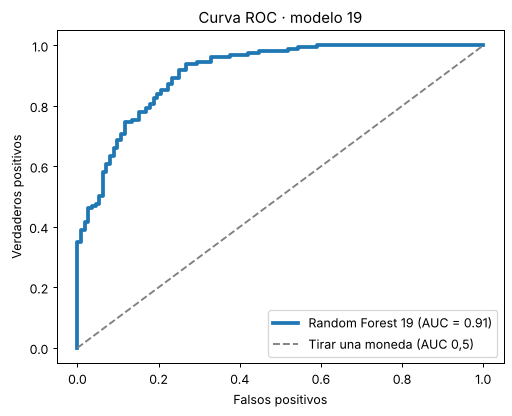

In [21]:
columna_si_19 = list(modelo_19.classes_).index("Sí")                     # posición de la clase "Sí" en predict_proba
prob_19 = modelo_19.predict_proba(X_test_19)[:, columna_si_19]           # probabilidad de "Sí" para cada persona del test
auc_19 = roc_auc_score(y_test_19 == "Sí", prob_19)                       # AUC: compara probabilidad con la respuesta real
print(f"AUC: {auc_19:.3f}")

fpr_19, tpr_19, _ = roc_curve(y_test_19 == "Sí", prob_19)                # puntos de la curva para cada umbral
plt.plot(fpr_19, tpr_19, linewidth=3, label=f"Random Forest 19 (AUC = {auc_19:.2f})")   # la curva ROC
plt.plot([0, 1], [0, 1], "--", color="grey", label="Tirar una moneda (AUC 0,5)")       # la diagonal del azar
plt.xlabel("Falsos positivos"); plt.ylabel("Verdaderos positivos")
plt.legend(); plt.title("Curva ROC · modelo 19"); plt.show()

#### 5.4 ¿Qué preguntas usa más el modelo? Importancia por permutación

Para cada variable, **desordeno al azar** sus valores en el test (10 veces) y miro **cuánto baja el AUC**. Si baja mucho, el modelo la necesitaba para acertar; si no cambia, no la usaba.

Uso la importancia por permutación y no la de Gini (`feature_importances_`), porque la de Gini favorece a las variables con muchas categorías y la de permutación se mide con datos que el modelo no ha visto.

Como una pregunta categórica puede tener varias columnas (dummies), sumo la importancia de todas las columnas de la misma pregunta (con `pregunta_de`). **Ojo:** dice qué preguntas usa el modelo para acertar, **no qué causa qué**.

In [22]:
perm_19 = permutation_importance(modelo_19, X_test_19, y_test_19,        # desordeno cada columna del test...
                                 scoring="roc_auc",                      # ...y mido cuánto baja el AUC
                                 n_repeats=10, random_state=SEMILLA, n_jobs=-1)   # 10 veces cada una

importancia_19 = pd.Series(perm_19.importances_mean, index=X_test_19.columns)   # importancia de cada columna
importancia_19 = importancia_19.groupby(pregunta_de).sum().sort_values(ascending=False)   # sumo por pregunta
importancia_19.head(10).round(4).to_frame("caída del AUC")               # las 10 que más pesan

,caída del AUC
p57_comodo_fisica_o_mental_companeros,0.0253
p81_reaccion_companeros_0_10,0.0226
p28_anterior_hablaria_supervisor,0.0164
p17_facilidad_pedir_baja,0.0150
p65_importancia_salud_mental,0.0129
p58_hablo_con_empleador,0.0091
p85_nota_al_sector_1_5,0.0088
p30_lo_contaria_amigos_familia,0.0058
p49_interfiere_sin_tratamiento,0.0031
p77_anterior_importancia_mental,0.0030


## Modelo 33 · ¿Tiene un trastorno ahora?

Mismos pasos que el modelo 19, con sus propias variables. La clase positiva es «Sí» (tiene un trastorno).

> **Qué error es peor en el modelo 33: el falso negativo.** El modelo dice que la persona **no** tiene un trastorno, pero **sí** lo tiene. Esa persona se quedaría sin la ayuda que necesita. Por eso aquí miro sobre todo el **recall del «Sí»**: de las personas con trastorno, ¿cuántas detecta?

Accuracy: 88.0% · Error: 12.0% · AUC: 0.931
Falsos negativos (tiene trastorno, pero el modelo dice que no): 8
              precision    recall  f1-score   support

          Sí       0.86      0.95      0.91       172
          No       0.91      0.77      0.83       112

    accuracy                           0.88       284
   macro avg       0.89      0.86      0.87       284
weighted avg       0.88      0.88      0.88       284



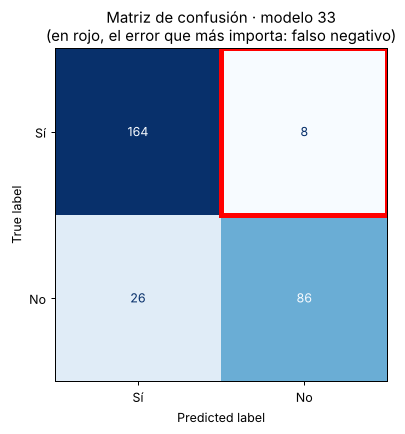

In [23]:
y_33 = target_33                                                         # la respuesta: "Sí" o "No"
X_train_33, X_test_33, y_train_33, y_test_33 = train_test_split(        # 2. TRAIN / TEST
    X_33, y_33, test_size=0.3, random_state=SEMILLA, stratify=y_33)      # 70 / 30, estratificado

modelo_33 = RandomForestClassifier(n_estimators=500, max_features="sqrt",   # mismos parámetros que el 19
                                   min_samples_leaf=5, random_state=SEMILLA, n_jobs=-1)
modelo_33.fit(X_train_33, y_train_33)                                    # 3. FIT: aprende con el 70 %
y_pred_33 = modelo_33.predict(X_test_33)                                 # 4. PREDICT: "Sí" o "No" para el 30 %

etiquetas_33 = ["Sí", "No"]                                              # 5. EVALUAR: primero la clase positiva
matriz_33 = confusion_matrix(y_test_33, y_pred_33, labels=etiquetas_33)  # matriz de confusión
accuracy_33 = accuracy_score(y_test_33, y_pred_33)                       # % de aciertos
prob_33 = modelo_33.predict_proba(X_test_33)[:, list(modelo_33.classes_).index("Sí")]   # probabilidad de "Sí"
auc_33 = roc_auc_score(y_test_33 == "Sí", prob_33)                       # AUC

ConfusionMatrixDisplay(matriz_33, display_labels=etiquetas_33).plot(cmap="Blues", colorbar=False)
plt.gca().add_patch(plt.Rectangle((0.5, -0.5), 1, 1, fill=False, edgecolor="red", linewidth=4))   # recuadro: fila "Sí", columna "No"
plt.title("Matriz de confusión · modelo 33\n(en rojo, el error que más importa: falso negativo)"); plt.show()

print(f"Accuracy: {accuracy_33:.1%} · Error: {1 - accuracy_33:.1%} · AUC: {auc_33:.3f}")
print("Falsos negativos (tiene trastorno, pero el modelo dice que no):", matriz_33[0, 1])
print(classification_report(y_test_33, y_pred_33, labels=etiquetas_33))

In [24]:
perm_33 = permutation_importance(modelo_33, X_test_33, y_test_33, scoring="roc_auc",   # importancia por permutación
                                 n_repeats=10, random_state=SEMILLA, n_jobs=-1)
importancia_33 = (pd.Series(perm_33.importances_mean, index=X_test_33.columns)          # importancia de cada columna
                  .groupby(pregunta_de).sum().sort_values(ascending=False))             # sumada por pregunta
importancia_33.head(10).round(4).to_frame("caída del AUC")

,caída del AUC
p07_ha_buscado_tratamiento,0.1640
p78_se_le_identifica,0.0059
p17_facilidad_pedir_baja,0.0057
p06_antecedentes_familiares,0.0039
p60_hablo_con_companeros,0.0036
edad,0.0031
p56_vio_mala_respuesta,0.0031
p58_hablo_con_empleador,0.0028
p65_importancia_salud_mental,0.0014
p14_conoce_opciones_atencion,0.0013


## Modelo 49 · Sin tratamiento, ¿le interfiere «a menudo» en el trabajo?

Mismos pasos, con sus propias variables. Solo personas con un trastorno. La clase positiva es «A menudo».

> **Qué error es peor en el modelo 49: el falso negativo.** El modelo dice que el trastorno **no** le afecta a menudo, pero **sí** le afecta. La empresa no le daría apoyo (flexibilidad, menos carga) justo a quien más le afecta en el trabajo. Por eso aquí miro sobre todo el **recall de «A menudo»**.

Accuracy: 69.0% · Error: 31.0% · AUC: 0.688
Falsos negativos (le afecta a menudo, pero el modelo dice que no): 29
              precision    recall  f1-score   support

    A menudo       0.72      0.83      0.77       167
 No a menudo       0.62      0.47      0.53       101

    accuracy                           0.69       268
   macro avg       0.67      0.65      0.65       268
weighted avg       0.68      0.69      0.68       268



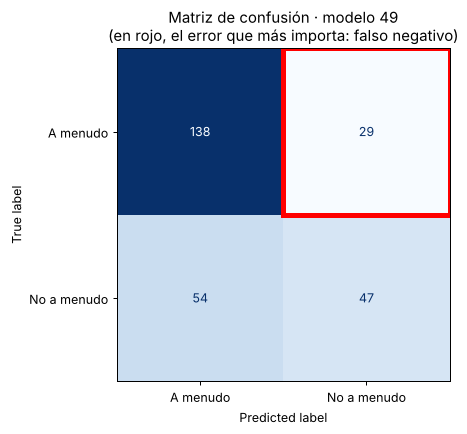

In [25]:
y_49 = target_49                                                         # la respuesta: "A menudo" o "No a menudo"
X_train_49, X_test_49, y_train_49, y_test_49 = train_test_split(        # 2. TRAIN / TEST
    X_49, y_49, test_size=0.3, random_state=SEMILLA, stratify=y_49)      # 70 / 30, estratificado

modelo_49 = RandomForestClassifier(n_estimators=500, max_features="sqrt",   # mismos parámetros que el 19
                                   min_samples_leaf=5, random_state=SEMILLA, n_jobs=-1)
modelo_49.fit(X_train_49, y_train_49)                                    # 3. FIT: aprende con el 70 %
y_pred_49 = modelo_49.predict(X_test_49)                                 # 4. PREDICT: para el 30 %

etiquetas_49 = ["A menudo", "No a menudo"]                               # 5. EVALUAR: primero la clase positiva
matriz_49 = confusion_matrix(y_test_49, y_pred_49, labels=etiquetas_49)  # matriz de confusión
accuracy_49 = accuracy_score(y_test_49, y_pred_49)                       # % de aciertos
prob_49 = modelo_49.predict_proba(X_test_49)[:, list(modelo_49.classes_).index("A menudo")]   # probabilidad de "A menudo"
auc_49 = roc_auc_score(y_test_49 == "A menudo", prob_49)                 # AUC

ConfusionMatrixDisplay(matriz_49, display_labels=etiquetas_49).plot(cmap="Blues", colorbar=False)
plt.gca().add_patch(plt.Rectangle((0.5, -0.5), 1, 1, fill=False, edgecolor="red", linewidth=4))   # recuadro: fila "A menudo", columna "No a menudo"
plt.title("Matriz de confusión · modelo 49\n(en rojo, el error que más importa: falso negativo)"); plt.show()

print(f"Accuracy: {accuracy_49:.1%} · Error: {1 - accuracy_49:.1%} · AUC: {auc_49:.3f}")
print("Falsos negativos (le afecta a menudo, pero el modelo dice que no):", matriz_49[0, 1])
print(classification_report(y_test_49, y_pred_49, labels=etiquetas_49))

In [26]:
perm_49 = permutation_importance(modelo_49, X_test_49, y_test_49, scoring="roc_auc",   # importancia por permutación
                                 n_repeats=10, random_state=SEMILLA, n_jobs=-1)
importancia_49 = (pd.Series(perm_49.importances_mean, index=X_test_49.columns)          # importancia de cada columna
                  .groupby(pregunta_de).sum().sort_values(ascending=False))             # sumada por pregunta
importancia_49.head(10).round(4).to_frame("caída del AUC")

,caída del AUC
p33_trastorno_actual,0.0997
edad,0.0140
p06_antecedentes_familiares,0.0067
p58_hablo_con_empleador,0.0060
p70_anterior_hablo_con_empleador,0.0034
p07_ha_buscado_tratamiento,0.0029
p12_lo_diria_en_entrevista,0.0028
p56_vio_mala_respuesta,0.0024
p27_anterior_anonimato,0.0022
p14_conoce_opciones_atencion,0.0018


## Los tres modelos juntos

Junto los resultados de los tres modelos en una tabla. En la columna **«recall que importa»** está el recall de la clase cuyo error es peor en cada modelo (ver los recuadros de cada modelo).

In [27]:
from sklearn.metrics import recall_score                                 # recall de una clase concreta

resumen = pd.DataFrame({
    "19 · supervisor": {"personas (train / test)": f"{len(X_train_19)} / {len(X_test_19)}", "columnas": X_19.shape[1],
                        "accuracy": accuracy_19, "error": 1 - accuracy_19, "AUC": auc_19,
                        "error que importa": "falso positivo", "recall que importa": recall_score(y_test_19, y_pred_19, pos_label="No")},
    "33 · trastorno": {"personas (train / test)": f"{len(X_train_33)} / {len(X_test_33)}", "columnas": X_33.shape[1],
                       "accuracy": accuracy_33, "error": 1 - accuracy_33, "AUC": auc_33,
                       "error que importa": "falso negativo", "recall que importa": recall_score(y_test_33, y_pred_33, pos_label="Sí")},
    "49 · interfiere": {"personas (train / test)": f"{len(X_train_49)} / {len(X_test_49)}", "columnas": X_49.shape[1],
                        "accuracy": accuracy_49, "error": 1 - accuracy_49, "AUC": auc_49,
                        "error que importa": "falso negativo", "recall que importa": recall_score(y_test_49, y_pred_49, pos_label="A menudo")},
}).T
resumen.round(3)

,personas (train / test),columnas,accuracy,error,AUC,error que importa,recall que importa
19 · supervisor,612 / 263,102,0.825095,0.174905,0.910241,falso positivo,0.776786
33 · trastorno,661 / 284,98,0.880282,0.119718,0.930855,falso negativo,0.953488
49 · interfiere,623 / 268,105,0.690299,0.309701,0.687674,falso negativo,0.826347


In [28]:
# Las 8 preguntas que más pesan en cada modelo
pd.concat({"19 · supervisor": importancia_19.head(8).round(4).reset_index(),
           "33 · trastorno": importancia_33.head(8).round(4).reset_index(),
           "49 · interfiere": importancia_49.head(8).round(4).reset_index()}, axis=1)

19 · supervisor                       33 · trastorno                           49 · interfiere        
                                   index       0                        index       0                             index       0
0  p57_comodo_fisica_o_mental_companeros  0.0253   p07_ha_buscado_tratamiento  0.1640              p33_trastorno_actual  0.0997
1           p81_reaccion_companeros_0_10  0.0226         p78_se_le_identifica  0.0059                              edad  0.0140
2       p28_anterior_hablaria_supervisor  0.0164     p17_facilidad_pedir_baja  0.0057       p06_antecedentes_familiares  0.0067
3               p17_facilidad_pedir_baja  0.0150  p06_antecedentes_familiares  0.0039           p58_hablo_con_empleador  0.0060
4           p65_importancia_salud_mental  0.0129     p60_hablo_con_companeros  0.0036  p70_anterior_hablo_con_empleador  0.0034
5                p58_hablo_con_empleador  0.0091                         edad  0.0031        p07_ha_buscado_tratamiento  0.0029
6                 p85_nota_al_sector_1_5  0.0088       p56_vio_mala_respuesta  0.0031        p12_lo_diria_en_entrevista  0.0028
7         p30_lo_contaria_amigos_familia  0.0058      p58_hablo_con_empleador  0.0028            p56_vio_mala_respuesta  0.0024

In [29]:
# Guardo los resultados en un diccionario SOLO para dibujar los gráficos de abajo (no se vuelve a entrenar nada)
TITULOS = {"19": "¿Hablaría con su supervisor? (19)", "33": "¿Tiene un trastorno ahora? (33)",
           "49": "¿Le interfiere a menudo en el trabajo? (49)"}
resultados = {
    "19": {"y_test": y_test_19, "y_pred": y_pred_19, "prob": prob_19, "pos": "Sí", "etiquetas": etiquetas_19,
           "accuracy": accuracy_19, "auc": auc_19, "importancia": importancia_19, "target": target_19,
           "n_train": len(X_train_19), "n_test": len(X_test_19), "error_clave": "falso positivo"},
    "33": {"y_test": y_test_33, "y_pred": y_pred_33, "prob": prob_33, "pos": "Sí", "etiquetas": etiquetas_33,
           "accuracy": accuracy_33, "auc": auc_33, "importancia": importancia_33, "target": target_33,
           "n_train": len(X_train_33), "n_test": len(X_test_33), "error_clave": "falso negativo"},
    "49": {"y_test": y_test_49, "y_pred": y_pred_49, "prob": prob_49, "pos": "A menudo", "etiquetas": etiquetas_49,
           "accuracy": accuracy_49, "auc": auc_49, "importancia": importancia_49, "target": target_49,
           "n_train": len(X_train_49), "n_test": len(X_test_49), "error_clave": "falso negativo"},
}

## Destilar la encuesta: de 48 preguntas a una encuesta corta para empresas

**El objetivo de esta parte.** Parto de una encuesta general (OSMI) y uso el Random Forest para **destilarla**: saber qué preguntas ayudan más a anticipar mi objetivo y quedarme solo con esas. Así una empresa puede usar una encuesta corta, anónima y sin datos de salud para saber en qué equipos la gente callaría.

Lo hago en dos pasos:

1. **Compruebo que la 19 es el mejor objetivo**, comparándola con otras preguntas que también podrían hacer de «puerta».
2. **Compruebo que con pocas preguntas se acierta casi igual que con las 48 del modelo 19.**

### 1. ¿Es la 19 la mejor pregunta objetivo?

Repito el mismo Random Forest con otras cuatro candidatas y miro tres cosas:

- **AUC:** si el modelo acierta.
- **Peso de la empresa:** qué % de la importancia viene de los temas de empresa y clima (empresa actual, empresas anteriores, actitud ante hablar, clima y experiencias).
- **% de «sí»:** si la pregunta está equilibrada.

Los 8 temas de cada pregunta los leo de `01_datos/auxiliares/tema_de_cada_pregunta.csv`, una tabla auxiliar donde asigné cada pregunta a su tema.

In [30]:
temas = pd.read_csv(BASE / "01_datos" / "auxiliares" / "tema_de_cada_pregunta.csv").drop_duplicates("pregunta_id")   # el tema de cada pregunta
TEMA_DE = dict(zip(temas["pregunta_id"].astype(str), temas["bloque"]))                              # "57" → "E. Disposición a hablar"
PERFIL = {"edad": "edad", "genero": "genero", "zona": "zona", "anio_encuesta": "anio",
          "tamano_empresa": "tamano", "empresa_tecnologica": "empresa_tech"}                       # las variables de perfil no tienen número

def tema_de(variable):
    clave = PERFIL.get(variable, str(int(variable.split("_")[0][1:])) if variable.startswith("p") else variable)   # "p57_..." → "57"
    return TEMA_DE[clave]                                                                           # devuelve su tema

TEMAS_EMPRESA = ["C. Empresa actual", "D. Empresas anteriores", "E. Disposición a hablar", "H. Clima y experiencias"]

def probar_objetivo(nombre, y, quitar):
    columnas = [c for c in tabla_preprocesada.columns if pregunta_de(c) not in quitar]   # todas menos el objetivo y sus "gemelas"
    X = tabla_preprocesada.loc[y.index, columnas]                                         # solo las personas con respuesta clara
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=SEMILLA, stratify=y)   # 70 / 30
    rf = RandomForestClassifier(n_estimators=300, max_features="sqrt", min_samples_leaf=5,
                                random_state=SEMILLA, n_jobs=-1).fit(X_tr, y_tr)          # mismo modelo que antes
    auc = roc_auc_score(y_te == "Sí", rf.predict_proba(X_te)[:, list(rf.classes_).index("Sí")])   # AUC
    perm = permutation_importance(rf, X_te, y_te, scoring="roc_auc", n_repeats=5, random_state=SEMILLA, n_jobs=-1)
    imp = pd.Series(perm.importances_mean, index=columnas).groupby(pregunta_de).sum().clip(lower=0)   # importancia por pregunta
    por_tema = imp.groupby(tema_de).sum() / imp.sum() * 100                                # % de la importancia por tema
    return {"objetivo": nombre, "personas": len(y), "% sí": round((y == "Sí").mean() * 100),
            "AUC": round(auc, 2), "% empresa": round(por_tema.reindex(TEMAS_EMPRESA).sum()),
            "3 que más pesan": ", ".join(imp.sort_values(ascending=False).index[:3])}

def solo_si_no(columna):
    respuestas = datos[columna]                                                           # la columna tal cual
    return respuestas[respuestas.isin(["Sí", "No"])]                                      # quito "Quizá" y "No lo sé"

hablo = datos["p58_hablo_con_empleador"].map({"1": "Sí", "0": "No", 1: "Sí", 0: "No"})   # 58 viene como 1 / 0
hablo = hablo[datos["p33_trastorno_actual"] == "Sí"]                                      # solo tiene sentido si hay un trastorno

candidatas = pd.DataFrame([
    probar_objetivo("19 · hablaría con su supervisor", solo_si_no("p19_hablaria_con_supervisor"),
                    ["p19_hablaria_con_supervisor", "p18_hablaria_con_companeros"]),
    probar_objetivo("18 · hablaría con sus compañeros", solo_si_no("p18_hablaria_con_companeros"),
                    ["p18_hablaria_con_companeros", "p19_hablaria_con_supervisor"]),
    probar_objetivo("58 · ya lo ha hablado con su empleador", hablo,
                    ["p58_hablo_con_empleador", "p33_trastorno_actual"]),
    probar_objetivo("12 · lo diría en una entrevista", solo_si_no("p12_lo_diria_en_entrevista"),
                    ["p12_lo_diria_en_entrevista", "p29_diria_salud_fisica_entrevista"]),
])
candidatas

,objetivo,personas,% sí,AUC,% empresa,3 que más pesan
0,19 · hablaría con su supervisor,875,58,0.91,90,"p57_comodo_fisica_o_mental_companeros, p81_reaccion_companeros_0_10, p28_anterior_hablaria_supervisor"
1,18 · hablaría con sus compañeros,734,55,0.96,98,"p57_comodo_fisica_o_mental_companeros, p60_hablo_con_companeros, p81_reaccion_companeros_0_10"
2,58 · ya lo ha hablado con su empleador,573,48,0.83,99,"p60_hablo_con_companeros, p19_hablaria_con_supervisor, p78_se_le_identifica"
3,12 · lo diría en una entrevista,979,7,0.80,85,"p78_se_le_identifica, p76_anterior_importancia_fisica, p28_anterior_hablaria_supervisor"


**Por qué me quedo con la 19:**

- **18 (compañeros):** acierta más, pero sus preguntas más importantes también hablan de los compañeros (57, 60). Es casi preguntar lo mismo dos veces. Además, a la empresa le llega la información por el supervisor, no por los compañeros.
- **58 (ya lo ha hablado):** es conducta real, pero solo tiene sentido si la persona ya tiene un problema y la explican otras conductas, no el clima. La uso como **validación de la 19**: quien se siente cómodo lo ha contado de verdad mucho más (lo calculo abajo).
- **12 (entrevista):** solo el 7 % dice que sí. Está muy desequilibrada.

La 19 es la puerta de la empresa, la puede responder todo el mundo y la explica el clima (90 %), que es lo que la empresa puede cambiar.

In [31]:
con_trastorno = datos[datos["p33_trastorno_actual"] == "Sí"]                              # 573 personas con trastorno
validacion = (con_trastorno.groupby("p19_hablaria_con_supervisor")["p58_hablo_con_empleador"]
              .apply(lambda s: round((s.astype(str) == "1").mean() * 100)))               # % que ya lo ha contado de verdad
validacion.to_frame("% que ya lo ha contado en su empresa")

,% que ya lo ha contado en su empresa
p19_hablaria_con_supervisor,
No,22
Quizá,37
Sí,76


### 2. ¿Cuántas preguntas hacen falta?

Vuelvo a entrenar el modelo 19 con **solo las N preguntas más importantes** y lo pruebo con el **mismo test** de 263 personas. Si acierta casi igual que con las 48, esas pocas preguntas bastan.

> **Preguntas que una empresa NO debe hacer.** Dentro de las 10 primeras hay tres que son datos de salud o personales: la 58 (si lo ha contado), la 49 (cuánto le interfiere) y la 30 (si lo contaría a su familia). Para la encuesta de empresa uso un **núcleo de 7 preguntas sin datos de salud**: las 5 primeras de clima (57, 81, 28, 17 y 65), la 11 (anonimato) y la 85 (nota al sector).

In [32]:
def probar_preguntas(nombre, preguntas):
    columnas = [c for c in X_train_19.columns if pregunta_de(c) in preguntas]            # columnas de esas preguntas
    rf = RandomForestClassifier(n_estimators=500, max_features="sqrt", min_samples_leaf=5,
                                random_state=SEMILLA, n_jobs=-1).fit(X_train_19[columnas], y_train_19)   # entreno con el mismo 70 %
    prob = rf.predict_proba(X_test_19[columnas])[:, list(rf.classes_).index("Sí")]        # pruebo con el mismo 30 %
    return {"encuesta": nombre, "preguntas": len(preguntas),
            "AUC": round(roc_auc_score(y_test_19 == "Sí", prob), 3),
            "recall del «No» (detecta a quien callaría)": round(recall_score(y_test_19, rf.predict(X_test_19[columnas]), pos_label="No"), 2)}

ranking_19 = list(importancia_19.index)                                                  # de más a menos importante
NUCLEO = ["p57_comodo_fisica_o_mental_companeros", "p81_reaccion_companeros_0_10", "p28_anterior_hablaria_supervisor",
          "p17_facilidad_pedir_baja", "p65_importancia_salud_mental", "p11_anonimato_protegido", "p85_nota_al_sector_1_5"]

destilacion = pd.DataFrame([
    probar_preguntas("Todas las del modelo 19 (las 50 menos la 18 y la 19)", ranking_19),
    probar_preguntas("Las 10 más importantes", ranking_19[:10]),
    probar_preguntas("Núcleo para empresas (sin datos de salud)", NUCLEO),
    probar_preguntas("Las 5 más importantes", ranking_19[:5]),
    probar_preguntas("Las 3 más importantes", ranking_19[:3]),
])
destilacion

,encuesta,preguntas,AUC,recall del «No» (detecta a quien callaría)
0,Todas las del modelo 19 (las 50 menos la 18 y la 19),48,0.910,0.78
1,Las 10 más importantes,10,0.904,0.79
2,Núcleo para empresas (sin datos de salud),7,0.913,0.81
3,Las 5 más importantes,5,0.899,0.80
4,Las 3 más importantes,3,0.862,0.77


**Lo que veo:** con el núcleo de 7 preguntas el modelo acierta prácticamente igual que con las 48. Es decir, el Random Forest me ha servido para **destilar la encuesta**: una empresa no necesita 48 preguntas, le bastan 7 sobre el clima, sin preguntar a nadie por su salud.

**Cómo lo usaría una empresa:** encuesta anónima con el núcleo de 7 preguntas, más la 19 y preguntas propias (área, carga de trabajo, si sabe a quién acudir, acceso a atención psicológica). Resultados solo por grupos de 5 personas o más. Tras la primera ronda, repite el Random Forest con sus datos para ver qué preguntas nuevas pesan.

> **Importante: el núcleo NO son las 7 primeras del ranking.**
>
> Son dos cosas distintas y conviene no mezclarlas:
>
> - **La curva** (prueba 3, más abajo) entrena con las k preguntas más importantes **en el orden del ranking**, incluidas la 58, la 30 y la 49, que una empresa no puede preguntar. Sirve para saber **cuántas** preguntas hacen falta: el acierto se aplana entre 5 y 7.
> - **El núcleo** son **mis 7 preguntas**, elegidas así: me quedo con las primeras del ranking que no son datos de salud ni personales (57, 81, 28, 17, 65 y 85) y **añado yo la 11 (anonimato)**, que está en el puesto 28, porque sin anonimato nadie respondería con sinceridad.
> - Con esas 7 **entreno un modelo nuevo** (solo con sus columnas, con el mismo 70 % de entrenamiento) y lo pruebo con el mismo 30 %. **El 98 % y las otras dos pruebas son de ese modelo**, no de la curva.
>
> En la tabla siguiente se ve el puesto de cada pregunta del núcleo en el ranking.

In [33]:
puestos = pd.DataFrame({"pregunta": NUCLEO,                                              # las 7 del núcleo
                        "puesto en el ranking": [ranking_19.index(p) + 1 for p in NUCLEO]})   # su posición (1 = la que más pesa)
puestos["por qué está"] = ["del ranking, sin datos de salud"] * 5 + ["la añado yo: anonimato", "del ranking, sin datos de salud"]
fuera = [p for p in ranking_19[:10] if p not in NUCLEO]                                  # de las 10 primeras, las que no entran
print("De las 10 primeras, fuera del núcleo:", fuera)                                    # 58, 30, 49 (salud o personales) y 77
puestos

De las 10 primeras, fuera del núcleo: ['p58_hablo_con_empleador', 'p30_lo_contaria_amigos_familia', 'p49_interfiere_sin_tratamiento', 'p77_anterior_importancia_mental']


,pregunta,puesto en el ranking,por qué está
0,p57_comodo_fisica_o_mental_companeros,1,"del ranking, sin datos de salud"
1,p81_reaccion_companeros_0_10,2,"del ranking, sin datos de salud"
2,p28_anterior_hablaria_supervisor,3,"del ranking, sin datos de salud"
3,p17_facilidad_pedir_baja,4,"del ranking, sin datos de salud"
4,p65_importancia_salud_mental,5,"del ranking, sin datos de salud"
5,p11_anonimato_protegido,28,la añado yo: anonimato
6,p85_nota_al_sector_1_5,7,"del ranking, sin datos de salud"


### 3. ¿Cómo demuestro que 7 preguntas bastan? Tres pruebas

Que el AUC salga parecido en un test podría ser suerte. Lo compruebo de tres formas:

1. **Intervalo de confianza de la diferencia (bootstrap).** Repito el test 2.000 veces cogiendo personas al azar (con reemplazo) y calculo cada vez la diferencia de AUC entre el núcleo de 7 y todas las preguntas. Si el intervalo del 95 % incluye el 0, no hay diferencia real.
2. **Validación cruzada.** Divido los datos de 5 formas distintas (5 *folds*): en cada una entreno con 4 partes y pruebo con la otra. Así no depende de una sola división 70/30.
3. **Curva por número de preguntas.** Entreno con la 1 más importante, luego con las 2, las 3… hasta 20, y dibujo el AUC. Busco el «codo»: el punto donde añadir más preguntas casi no mejora.

In [34]:
from sklearn.model_selection import StratifiedKFold, cross_val_score   # validación cruzada

columnas_nucleo = [c for c in X_train_19.columns if pregunta_de(c) in NUCLEO]          # columnas del núcleo de 7
modelo_nucleo = RandomForestClassifier(n_estimators=500, max_features="sqrt", min_samples_leaf=5,
                                       random_state=SEMILLA, n_jobs=-1).fit(X_train_19[columnas_nucleo], y_train_19)
prob_nucleo = modelo_nucleo.predict_proba(X_test_19[columnas_nucleo])[:, list(modelo_nucleo.classes_).index("Sí")]

# --- Prueba 1: bootstrap de la diferencia de AUC (mismo test) ---
real = (y_test_19 == "Sí").values                                                      # True si respondió "Sí"
azar = np.random.default_rng(SEMILLA)                                                  # generador de números al azar
diferencias = []
for _ in range(2000):                                                                  # 2.000 repeticiones
    i = azar.integers(0, len(real), len(real))                                         # personas al azar, con reemplazo
    if real[i].min() == real[i].max():                                                 # si solo salen "Sí" o solo "No", no se puede
        continue
    diferencias.append(roc_auc_score(real[i], prob_nucleo[i]) - roc_auc_score(real[i], prob_19[i]))   # núcleo − todas
bajo, alto = np.percentile(diferencias, [2.5, 97.5])                                   # intervalo del 95 %
print(f"AUC todas: {auc_19:.3f} · AUC núcleo de 7: {roc_auc_score(real, prob_nucleo):.3f}")
print(f"Diferencia (núcleo − todas): {np.mean(diferencias):+.3f} · IC 95 %: de {bajo:+.3f} a {alto:+.3f}")
print("¿Incluye el 0? →", "sí: no hay diferencia real" if bajo <= 0 <= alto else "no")

AUC todas: 0.910 · AUC núcleo de 7: 0.913
Diferencia (núcleo − todas): +0.003 · IC 95 %: de -0.017 a +0.023
¿Incluye el 0? → sí: no hay diferencia real


In [35]:
# --- Prueba 2: validación cruzada con 5 divisiones distintas ---
cinco = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)                # 5 divisiones con el mismo % de "Sí"
nuevo_rf = lambda: RandomForestClassifier(n_estimators=500, max_features="sqrt", min_samples_leaf=5,
                                          random_state=SEMILLA, n_jobs=-1)
cv_todas = cross_val_score(nuevo_rf(), X_19, y_19, cv=cinco, scoring="roc_auc")       # AUC de cada división, todas
cv_nucleo = cross_val_score(nuevo_rf(), X_19[columnas_nucleo], y_19, cv=cinco, scoring="roc_auc")   # AUC, núcleo de 7
print("AUC por división, todas:  ", np.round(cv_todas, 3), "→ media", round(cv_todas.mean(), 3))
print("AUC por división, núcleo: ", np.round(cv_nucleo, 3), "→ media", round(cv_nucleo.mean(), 3))
print(f"El núcleo conserva el {cv_nucleo.mean() / cv_todas.mean():.0%} del acierto con {len(NUCLEO)} de {len(ranking_19)} preguntas "
      f"({len(NUCLEO) / len(ranking_19):.0%})")

AUC por división, todas:   [0.903 0.895 0.921 0.852 0.904] → media 0.895
AUC por división, núcleo:  [0.896 0.878 0.893 0.845 0.893] → media 0.881
El núcleo conserva el 98% del acierto con 7 de 48 preguntas (15%)


In [36]:
# --- Prueba 3: curva del AUC según el número de preguntas ---
curva = []
for k in range(1, 21):                                                                 # de 1 a 20 preguntas
    cols_k = [c for c in X_train_19.columns if pregunta_de(c) in ranking_19[:k]]       # las k más importantes
    rf_k = nuevo_rf().fit(X_train_19[cols_k], y_train_19)                              # entreno con el mismo 70 %
    curva.append(roc_auc_score(y_test_19 == "Sí", rf_k.predict_proba(X_test_19[cols_k])[:, list(rf_k.classes_).index("Sí")]))
curva = pd.Series(curva, index=range(1, 21))                                           # AUC por número de preguntas
curva.round(3).to_frame("AUC").T

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
AUC,0.689,0.814,0.862,0.886,0.899,0.894,0.9,0.898,0.903,0.904,0.911,0.909,0.911,0.913,0.911,0.912,0.912,0.915,0.915,0.915


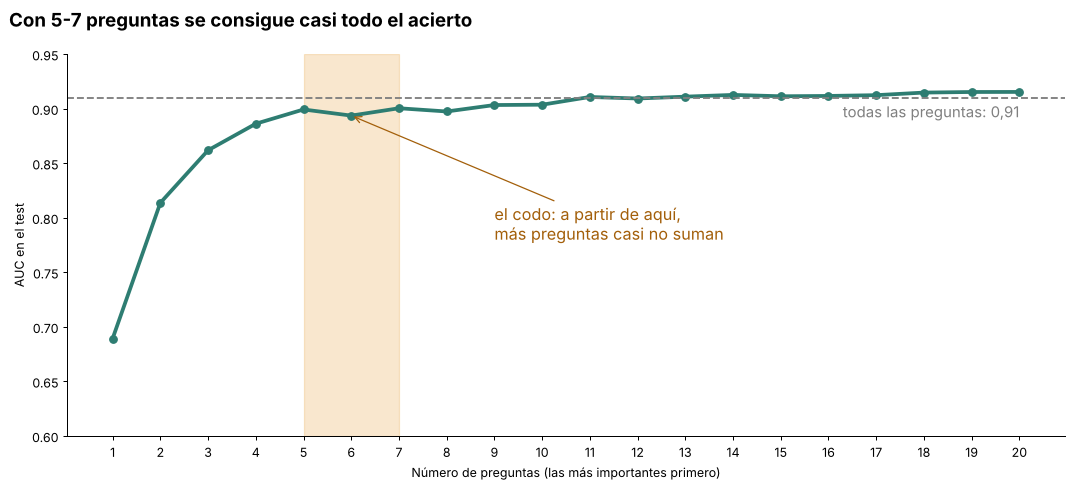

In [37]:
# --- 55. Gráfico de la curva: sube rápido y se aplana ---
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(curva.index, curva.values, color="#2E7D72", linewidth=3, marker="o")           # la curva
ax.axhline(auc_19, color="grey", linestyle="--")                                        # el AUC con todas
ax.text(20, auc_19 - 0.018, f"todas las preguntas: {auc_19:.2f}".replace(".", ","), ha="right", color="grey", fontsize=12)
ax.axvspan(5, 7, color="#E8A33D", alpha=0.25)                                           # la zona del codo
ax.annotate("el codo: a partir de aquí,\nmás preguntas casi no suman", xy=(6, curva[6]), xytext=(9, 0.78),
            arrowprops=dict(arrowstyle="->", color="#A35F0A"), fontsize=13, color="#A35F0A")
ax.set_xticks(range(1, 21)); ax.set_xlabel("Número de preguntas (las más importantes primero)")
ax.set_ylabel("AUC en el test"); ax.set_ylim(0.6, 0.95)
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
fig.suptitle("Con 5-7 preguntas se consigue casi todo el acierto", x=0.01, ha="left", fontsize=15, fontweight="bold")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "55_rf_curva_preguntas.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

**Lo que demuestran las tres pruebas:**

- El intervalo de la diferencia incluye el 0: en el test, el núcleo de 7 y todas las preguntas aciertan igual.
- En la validación cruzada el núcleo pierde una o dos centésimas: conserva alrededor del 98 % del acierto con el 15 % de las preguntas.
- La curva sube rápido con las primeras preguntas y se aplana entre 5 y 7.

En resumen: **«casi igual: conserva el 98 % del acierto con el 15 % de las preguntas»**. Y además ninguna de las 7 es sobre la salud, que es lo que pide el principio de **minimización de datos** del RGPD: recoger solo lo necesario.

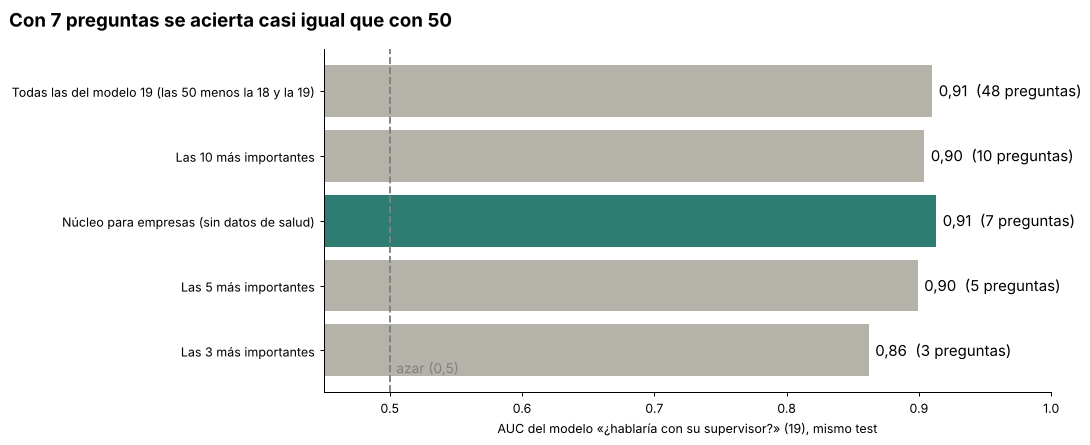

In [38]:
# --- 54. La destilación en un gráfico ---
fig, ax = plt.subplots(figsize=(12, 5))
colores_d = ["#B4B2A9", "#B4B2A9", "#2E7D72", "#B4B2A9", "#B4B2A9"]                          # el núcleo en verde
ax.barh(destilacion["encuesta"], destilacion["AUC"], color=colores_d)                          # una barra por encuesta
for i, (auc, n) in enumerate(zip(destilacion["AUC"], destilacion["preguntas"])):
    ax.text(auc + 0.005, i, f"{auc:.2f}  ({n} preguntas)".replace(".", ","), va="center", fontsize=12)   # AUC y nº de preguntas
ax.axvline(0.5, color="grey", linestyle="--"); ax.text(0.505, 4.35, "azar (0,5)", color="grey", fontsize=11)
ax.set_xlim(0.45, 1); ax.invert_yaxis(); ax.set_xlabel("AUC del modelo «¿hablaría con su supervisor?» (19), mismo test")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
fig.suptitle("Con 7 preguntas se acierta casi igual que con 50", x=0.01, ha="left", fontsize=15, fontweight="bold")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "54_rf_destilacion.png", dpi=200, bbox_inches="tight", facecolor="white")   # guardo en 04_figuras
plt.show()

## Gráficos del proceso para la presentación

Guardo en `04_figuras` los gráficos que enseñan el **proceso** (no solo el resultado):

- `40_rf_proceso.png`: los pasos del Random Forest con mis números.
- `41_rf_preprocesado_ejemplo.png`: cómo cambian los datos de una persona en el preprocesado.
- `42_rf_balance_clases.png`: cuántos sí y no hay en cada target.
- `43_rf_matrices_confusion.png`: matriz de confusión de los tres modelos.
- `44_rf_curvas_roc.png`: curvas ROC de los tres modelos.
- `45_rf_importancia.png`: las preguntas que más pesan en cada modelo.
- `46_rf_precision_recall_f1.png`: precision, recall y F1 de cada clase.

Guardado: 04_figuras/40_rf_proceso.png


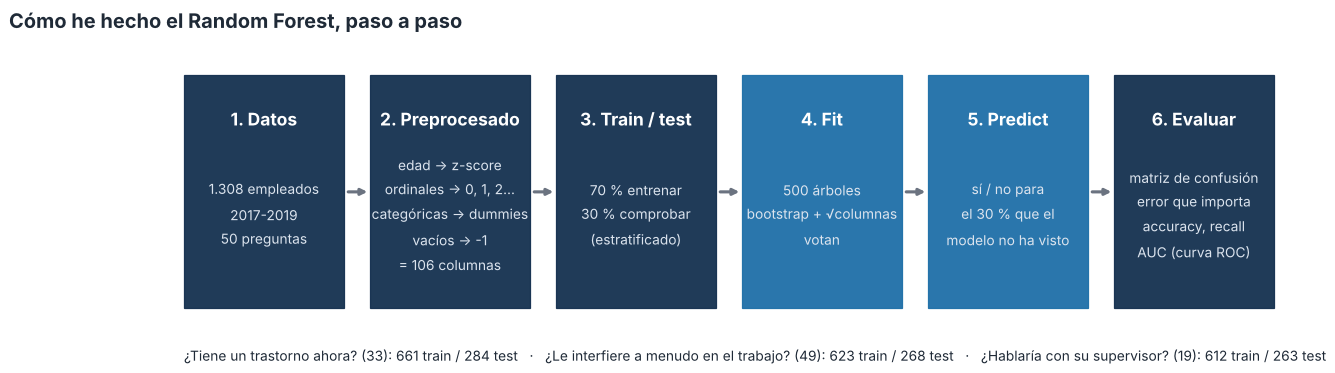

In [39]:
AZUL, CORAL, VERDE, TINTA, GRIS = "#1E6FA8", "#D9573E", "#3E8E5E", "#1F2A37", "#6B7380"   # colores del proyecto
COLOR = {"33": AZUL, "49": CORAL, "19": VERDE}
ORDEN = ["33", "49", "19"]                                               # orden de las fases: tenerlo, que afecte, contarlo

def guardar(fig, nombre):
    fig.savefig(RUTA_FIGURAS / nombre, dpi=200, bbox_inches="tight", facecolor="white")   # guardo en alta resolución
    print("Guardado: 04_figuras/" + nombre)

# --- 40. El proceso, paso a paso, con mis números ---
pasos = [("1. Datos", f"{len(datos):,} empleados\n2017-2019\n50 preguntas".replace(",", ".")),
         ("2. Preprocesado", f"edad → z-score\nordinales → 0, 1, 2…\ncategóricas → dummies\nvacíos → -1\n= {tabla_preprocesada.shape[1]} columnas"),
         ("3. Train / test", "70 % entrenar\n30 % comprobar\n(estratificado)"),
         ("4. Fit", "500 árboles\nbootstrap + √columnas\nvotan"),
         ("5. Predict", "sí / no para\nel 30 % que el\nmodelo no ha visto"),
         ("6. Evaluar", "matriz de confusión\nerror que importa\naccuracy, recall\nAUC (curva ROC)")]
fig, ax = plt.subplots(figsize=(16, 4.2)); ax.axis("off")
for i, (titulo, texto) in enumerate(pasos):
    x = i * 1.0
    ax.add_patch(plt.Rectangle((x, 0.1), 0.86, 0.8, color=AZUL if i in (3, 4) else "#14304F", alpha=0.95))
    ax.text(x + 0.43, 0.75, titulo, ha="center", va="center", fontsize=14, fontweight="bold", color="white")
    ax.text(x + 0.43, 0.42, texto, ha="center", va="center", fontsize=11, color="#DCE4EE", linespacing=1.5)
    if i < len(pasos) - 1:
        ax.annotate("", xy=(x + 1.0, 0.5), xytext=(x + 0.87, 0.5), arrowprops=dict(arrowstyle="-|>", color=GRIS, lw=2.5))
ax.set_xlim(-0.05, 5.95); ax.set_ylim(0, 1)
filas = "   ·   ".join(f"{TITULOS[m]}: {resultados[m]['n_train']} train / {resultados[m]['n_test']} test" for m in ORDEN)
ax.text(0, -0.08, filas, fontsize=11, color=TINTA)
fig.suptitle("Cómo he hecho el Random Forest, paso a paso", x=0.01, ha="left", fontsize=16, fontweight="bold", color=TINTA)
guardar(fig, "40_rf_proceso.png")

Guardado: 04_figuras/41_rf_preprocesado_ejemplo.png


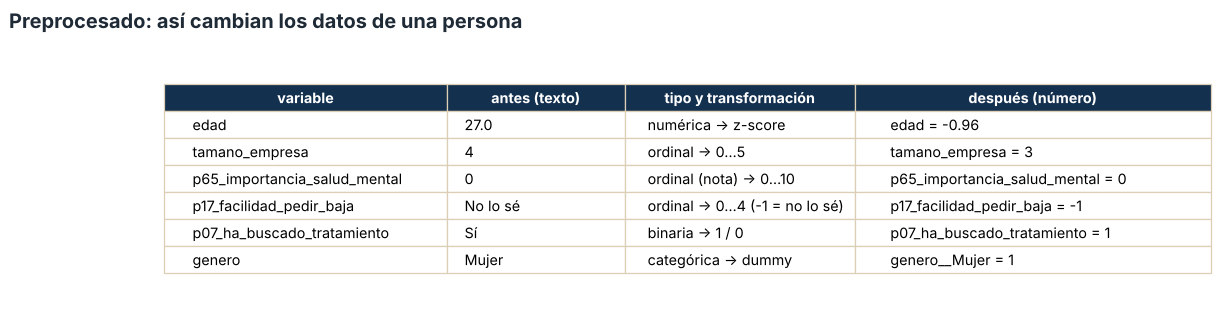

In [40]:
# --- 41. Ejemplo de preprocesado: una persona antes y después ---
persona = datos.index[0]                                                 # cojo la primera persona como ejemplo
ejemplo_cols = [("edad", "edad"), ("tamano_empresa", "tamano_empresa"), ("p17_facilidad_pedir_baja", "p17_facilidad_pedir_baja"),
                ("p07_ha_buscado_tratamiento", "p07_ha_buscado_tratamiento"), ("genero", "genero__Mujer")]
ejemplo_cols.insert(2, ("p65_importancia_salud_mental", "p65_importancia_salud_mental"))   # una nota de 0 a 10
tipo_ej = ["numérica → z-score", "ordinal → 0…5", "ordinal (nota) → 0…10", "ordinal → 0…4 (-1 = no lo sé)", "binaria → 1 / 0", "categórica → dummy"]
filas_ej = [[a, str(datos.loc[persona, a]), t, f"{b} = {tabla_preprocesada.loc[persona, b]:.2f}" if isinstance(tabla_preprocesada.loc[persona, b], float)
             else f"{b} = {tabla_preprocesada.loc[persona, b]}"] for (a, b), t in zip(ejemplo_cols, tipo_ej)]
fig, ax = plt.subplots(figsize=(15, 3.9)); ax.axis("off")
t = ax.table(cellText=filas_ej, colLabels=["variable", "antes (texto)", "tipo y transformación", "después (número)"],
             loc="center", cellLoc="left", colWidths=[0.27, 0.17, 0.22, 0.34])
t.auto_set_font_size(False); t.set_fontsize(11.5); t.scale(1, 1.8)
for (r, c), cell in t.get_celld().items():
    cell.set_edgecolor("#DDCFB6")
    if r == 0: cell.set_facecolor("#14304F"); cell.set_text_props(color="white", fontweight="bold")
fig.suptitle("Preprocesado: así cambian los datos de una persona", x=0.01, ha="left", fontsize=16, fontweight="bold", color=TINTA)
guardar(fig, "41_rf_preprocesado_ejemplo.png")

Guardado: 04_figuras/42_rf_balance_clases.png


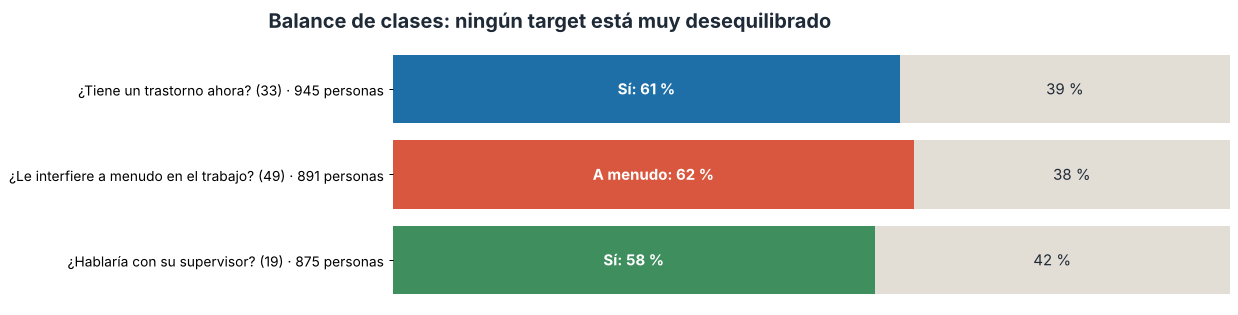

In [41]:
# --- 42. Balance de clases de cada target ---
fig, ax = plt.subplots(figsize=(12, 3.8))
for i, m in enumerate(ORDEN):
    pos = (resultados[m]["target"] == resultados[m]["pos"]).mean() * 100   # % de la clase positiva
    ax.barh(i, pos, color=COLOR[m]); ax.barh(i, 100 - pos, left=pos, color="#E3DED5")
    ax.text(pos / 2, i, f"{resultados[m]['pos']}: {pos:.0f} %", ha="center", va="center", color="white", fontsize=12, fontweight="bold")
    ax.text(pos + (100 - pos) / 2, i, f"{100 - pos:.0f} %", ha="center", va="center", color=TINTA, fontsize=12)
ax.set_yticks(range(3)); ax.set_yticklabels([f"{TITULOS[m]} · {len(resultados[m]['target'])} personas" for m in ORDEN], fontsize=11)
ax.set_xlim(0, 100); ax.invert_yaxis(); ax.set_xticks([]); [s.set_visible(False) for s in ax.spines.values()]
fig.suptitle("Balance de clases: ningún target está muy desequilibrado", x=0.01, ha="left", fontsize=16, fontweight="bold", color=TINTA)
guardar(fig, "42_rf_balance_clases.png")

Guardado: 04_figuras/43_rf_matrices_confusion.png
Guardado: 04_figuras/44_rf_curvas_roc.png


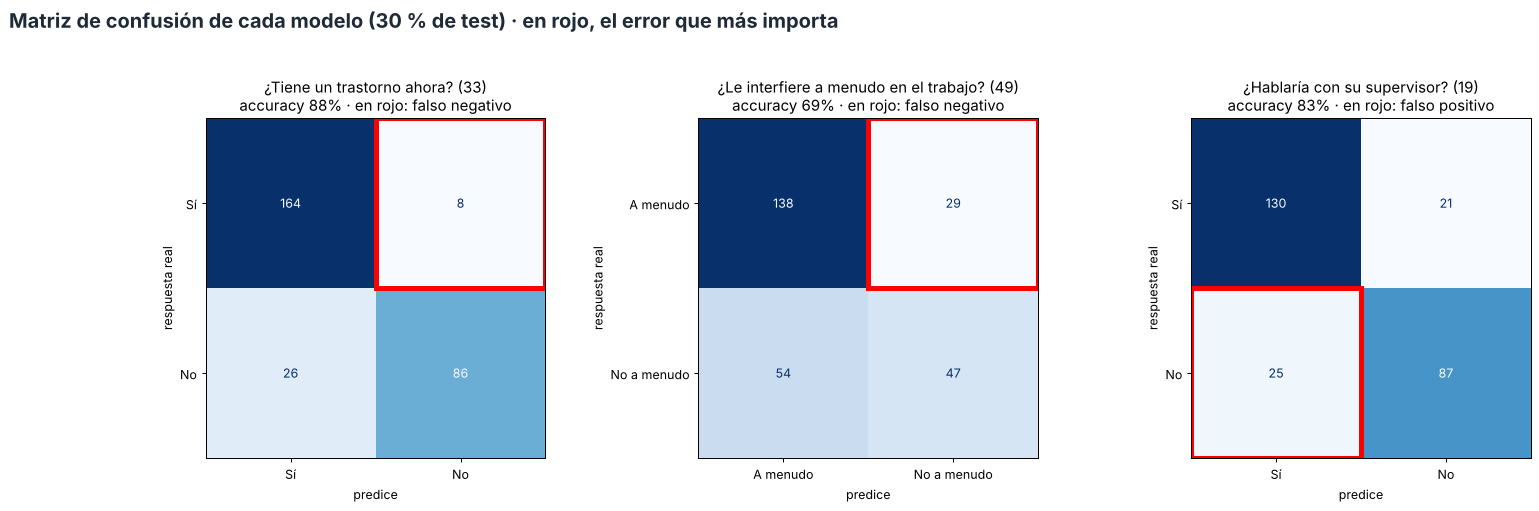

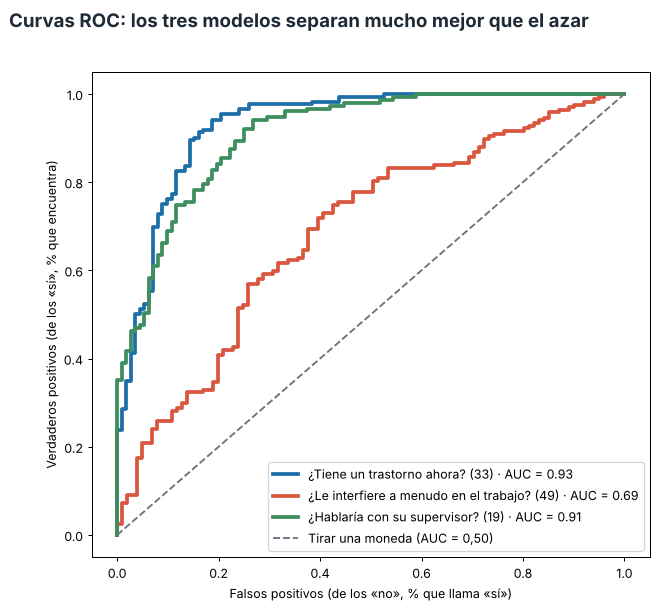

In [42]:
# --- 43. Matrices de confusión de los tres modelos ---
fig, ejes = plt.subplots(1, 3, figsize=(19, 5.6))
fig.subplots_adjust(wspace=0.45)                                      # espacio entre las tres matrices
for ax, m in zip(ejes, ORDEN):
    r = resultados[m]
    etiquetas = r["etiquetas"]                                            # primero la positiva
    ConfusionMatrixDisplay(confusion_matrix(r["y_test"], r["y_pred"], labels=etiquetas),
                           display_labels=etiquetas).plot(ax=ax, cmap="Blues", colorbar=False)
    esquina = (-0.5, 0.5) if r["error_clave"] == "falso positivo" else (0.5, -0.5)   # casilla del error que importa
    ax.add_patch(plt.Rectangle(esquina, 1, 1, fill=False, edgecolor="red", linewidth=4))   # la marco en rojo
    ax.set_title(f"{TITULOS[m]}\naccuracy {r['accuracy']:.0%} · en rojo: {r['error_clave']}", fontsize=12)
    ax.set_xlabel("predice"); ax.set_ylabel("respuesta real")
fig.suptitle("Matriz de confusión de cada modelo (30 % de test) · en rojo, el error que más importa", x=0.01, ha="left", fontsize=16, fontweight="bold", color=TINTA, y=1.05)
guardar(fig, "43_rf_matrices_confusion.png")

# --- 44. Curvas ROC ---
fig, ax = plt.subplots(figsize=(8, 7))
for m in ORDEN:
    r = resultados[m]
    fpr, tpr, _ = roc_curve(r["y_test"] == r["pos"], r["prob"])          # puntos de la curva para cada umbral
    ax.plot(fpr, tpr, color=COLOR[m], linewidth=3, label=f"{TITULOS[m]} · AUC = {r['auc']:.2f}")
ax.plot([0, 1], [0, 1], "--", color=GRIS, label="Tirar una moneda (AUC = 0,50)")
ax.set_xlabel("Falsos positivos (de los «no», % que llama «sí»)"); ax.set_ylabel("Verdaderos positivos (de los «sí», % que encuentra)")
ax.legend(loc="lower right", fontsize=10)
fig.suptitle("Curvas ROC: los tres modelos separan mucho mejor que el azar", x=0.01, ha="left", fontsize=15, fontweight="bold", color=TINTA)
guardar(fig, "44_rf_curvas_roc.png")

Guardado: 04_figuras/45_rf_importancia.png


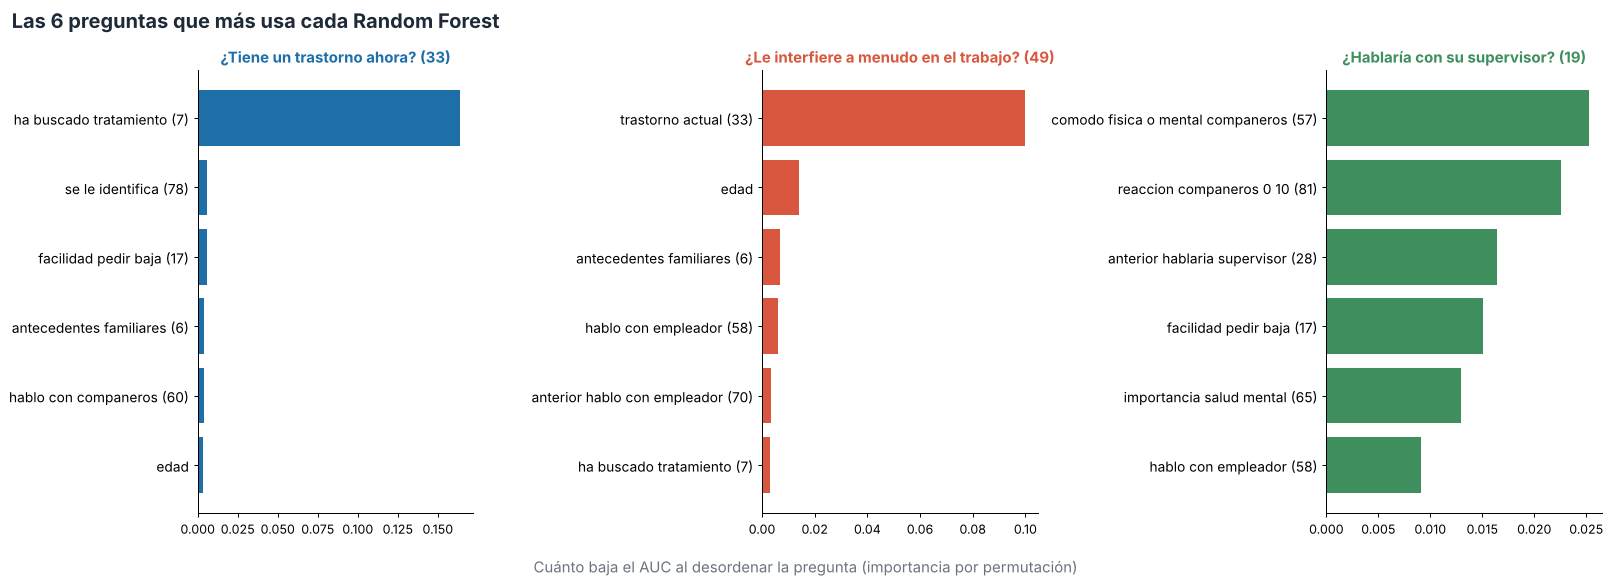

In [43]:
# --- 45. Las preguntas que más pesan en cada modelo ---
fig, ejes = plt.subplots(1, 3, figsize=(18, 6.5))
for ax, m in zip(ejes, ORDEN):
    top = resultados[m]["importancia"].head(6)[::-1]                     # las 6 más importantes
    nombres = [n.split("_", 1)[1].replace("_", " ") + f" ({n.split('_')[0][1:].lstrip('0')})"   # "p65_importancia..." → "importancia ... (65)"
               if n[0] == "p" and n[1].isdigit() else n.replace("_", " ") for n in top.index]          # "edad" se queda igual
    ax.barh(nombres, top.values, color=COLOR[m])
    ax.set_title(TITULOS[m], fontsize=12, color=COLOR[m], fontweight="bold")
    ax.tick_params(axis="y", labelsize=11); ax.spines["right"].set_visible(False); ax.spines["top"].set_visible(False)
fig.supxlabel("Cuánto baja el AUC al desordenar la pregunta (importancia por permutación)", fontsize=12, color=GRIS)
fig.suptitle("Las 6 preguntas que más usa cada Random Forest", x=0.01, ha="left", fontsize=16, fontweight="bold", color=TINTA)
fig.tight_layout()
guardar(fig, "45_rf_importancia.png")

**Cómo leer el gráfico 46:** el *accuracy* (en el título) es la nota global. Lo que importa en cada modelo es la **barra naranja (recall) de la clase clave**: el «No» en el 19, el «Sí» en el 33 y «A menudo» en el 49.

Guardado: 04_figuras/46_rf_precision_recall_f1.png


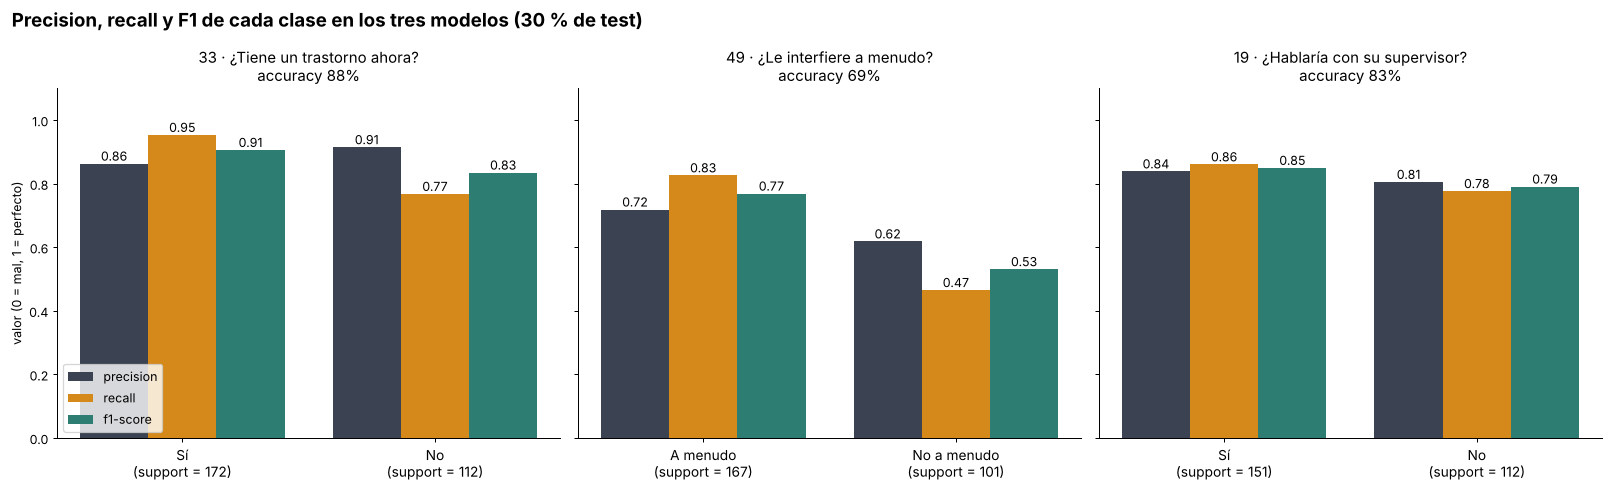

In [44]:
# --- 46. Precision, recall y F1 de cada clase (el informe del score, en gráfico) ---
from sklearn.metrics import classification_report                       # ya importada arriba; la repito por si acaso

modelos = [("33 · ¿Tiene un trastorno ahora?", y_test_33, y_pred_33, etiquetas_33),   # (título, real, predicción, clases)
           ("49 · ¿Le interfiere a menudo?",   y_test_49, y_pred_49, etiquetas_49),
           ("19 · ¿Hablaría con su supervisor?", y_test_19, y_pred_19, etiquetas_19)]
metricas = ["precision", "recall", "f1-score"]                           # las tres métricas que dibujo
colores = ["#3B4252", "#D4891A", "#2E7D72"]                              # un color por métrica

fig, ejes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)           # un gráfico por modelo, mismo eje vertical
for ax, (titulo, real, pred, clases) in zip(ejes, modelos):
    informe = classification_report(real, pred, labels=clases, output_dict=True)   # el informe como diccionario
    x = np.arange(len(clases))                                           # una posición por clase (Sí / No)
    for i, (m, color) in enumerate(zip(metricas, colores)):
        valores = [informe[c][m] for c in clases]                        # la métrica para cada clase
        barras = ax.bar(x + (i - 1) * 0.27, valores, width=0.27, color=color, label=m)   # barras agrupadas
        ax.bar_label(barras, fmt="%.2f", fontsize=10)                    # el número encima de cada barra
    ax.set_xticks(x)
    ax.set_xticklabels([f"{c}\n(support = {int(informe[c]['support'])})" for c in clases], fontsize=11)   # clase + cuántas personas
    ax.set_title(f"{titulo}\naccuracy {informe['accuracy']:.0%}", fontsize=12)
    ax.set_ylim(0, 1.1); ax.spines[["top", "right"]].set_visible(False)
ejes[0].set_ylabel("valor (0 = mal, 1 = perfecto)")
ejes[0].legend(loc="lower left")
fig.suptitle("Precision, recall y F1 de cada clase en los tres modelos (30 % de test)", x=0.01, ha="left", fontsize=15, fontweight="bold")
fig.tight_layout()
guardar(fig, "46_rf_precision_recall_f1.png")                           # lo guardo en 04_figuras
plt.show()

## Resumen para explicar el proceso en 30 segundos

1. **Datos:** 1.308 empleados de 2017-2019, 50 preguntas (sin la 48).
2. **Preprocesado:** todo a números. La edad con z-score, ordinales 0, 1, 2… (también las notas de 0 a 10), binarias 1/0 y categóricas con dummies (`drop_first=True`). Los vacíos, explícitos: −1 o «Sin respuesta». Quito de cada modelo el target y las preguntas que son la misma pregunta con otras palabras.
3. **Targets tal cual:** 19 = Sí / No (sin «Quizá»), 33 = Sí / No, 49 = «A menudo» frente al resto.
4. **Train / test:** 70 % para entrenar y 30 % para comprobar, estratificado.
5. **Fit:** Random Forest de 500 árboles; cada uno aprende con una muestra distinta y en cada corte mira solo algunas columnas al azar. Al final votan.
6. **Predict:** sí / no para el 30 % que el modelo no ha visto.
7. **Evaluar:** matriz de confusión con el error que más importa en cada modelo (19: falso positivo; 33 y 49: falso negativo), su recall, accuracy y error, y AUC con la curva ROC (cómo separa el sí del no, comparado con el 0,5 de tirar una moneda).
8. **Interpretar:** importancia por permutación. Dice qué preguntas usa el modelo, **no qué causa qué**.

## Gráficos del modelo 19 que uso en la presentación

Dibujo con los resultados de este notebook los gráficos del Random Forest que salen en la presentación. Los guardo en `04_figuras` con el prefijo `p_`. Uso siempre los mismos colores con el mismo significado: **verde** = hablaría, **coral** = callaría, **frambuesa** = tener un trastorno (modelo 33), **azul** = mi núcleo de 7 preguntas, **gris rayado** = datos de salud.

In [45]:
import matplotlib.pyplot as plt
VERDE, CORAL, FRAMBUESA, AZUL = "#2E7D72", "#D9634C", "#A23B72", "#2F6EA8"                   # un color = un significado
GRIS, GRIS2, TINTA, TINTA2 = "#CEC8BC", "#E7E1D6", "#15171C", "#5C6270"
plt.rcParams.update({"font.family": ["Inter", "DejaVu Sans"], "font.size": 16, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.edgecolor": GRIS})

def guardar_p(fig, nombre):
    fig.savefig(RUTA_FIGURAS / nombre, dpi=150, bbox_inches="tight", facecolor="white")      # lo guardo en 04_figuras
    print("Guardado: 04_figuras/" + nombre)

### Las preguntas que más pesan en el modelo 19 (% de la importancia total)

Paso la importancia por permutación a **% del total** para que se lea fácil. Marco en gris rayado las preguntas que son datos de salud o personales (una empresa no debe hacerlas) y añado la 11 (anonimato), que está en el puesto 28 pero forma parte de mi núcleo.

Guardado: 04_figuras/p_ranking_19.png


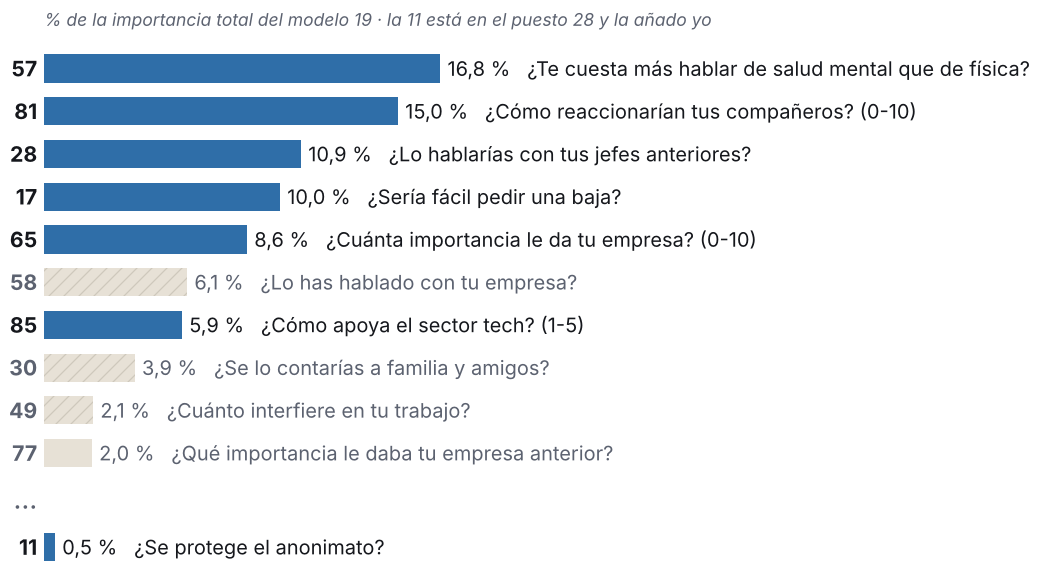

In [46]:
total_19 = importancia_19.clip(lower=0).sum()                                              # suma de las importancias positivas
pct_19 = importancia_19.clip(lower=0) / total_19 * 100                                     # % de la importancia total
FILAS = [("p57_comodo_fisica_o_mental_companeros", "¿Te cuesta más hablar de salud mental que de física?", "nucleo"),
         ("p81_reaccion_companeros_0_10", "¿Cómo reaccionarían tus compañeros? (0-10)", "nucleo"),
         ("p28_anterior_hablaria_supervisor", "¿Lo hablarías con tus jefes anteriores?", "nucleo"),
         ("p17_facilidad_pedir_baja", "¿Sería fácil pedir una baja?", "nucleo"),
         ("p65_importancia_salud_mental", "¿Cuánta importancia le da tu empresa? (0-10)", "nucleo"),
         ("p58_hablo_con_empleador", "¿Lo has hablado con tu empresa?", "salud"),
         ("p85_nota_al_sector_1_5", "¿Cómo apoya el sector tech? (1-5)", "nucleo"),
         ("p30_lo_contaria_amigos_familia", "¿Se lo contarías a familia y amigos?", "salud"),
         ("p49_interfiere_sin_tratamiento", "¿Cuánto interfiere en tu trabajo?", "salud"),
         ("p77_anterior_importancia_mental", "¿Qué importancia le daba tu empresa anterior?", "otra"),
         ("p11_anonimato_protegido", "¿Se protege el anonimato?", "anonimato")]
valores = [pct_19[c] for c, _, _ in FILAS]
fig, ax = plt.subplots(figsize=(14, 8.2))
posiciones = list(range(10)) + [11.2]                                                     # dejo un hueco antes de la 11
for y, (col, texto, tipo), v in zip(posiciones, FILAS, valores):
    salud = tipo == "salud"
    ax.barh(y, v, color=(GRIS2 if tipo in ("salud", "otra") else AZUL), height=0.66,
            hatch=("//" if salud else None), edgecolor=(GRIS if salud else "none"), lw=0)
    ax.text(-0.3, y, col.split("_")[0][1:], ha="right", va="center", fontsize=17, fontweight="bold",
            color=(TINTA if tipo in ("nucleo", "anonimato") else TINTA2))
    ax.text(v + 0.3, y, f"{v:.1f} %".replace(".", ",") + "   " + texto, va="center", fontsize=16,
            color=(TINTA if tipo in ("nucleo", "anonimato") else TINTA2))
puesto_11 = list(importancia_19.index).index("p11_anonimato_protegido") + 1
ax.text(-0.3, 10.25, "···", fontsize=22, color=TINTA2, va="center", ha="right")
ax.text(0, -1.0, f"% de la importancia total del modelo 19 · la 11 está en el puesto {puesto_11} y la añado yo",
        fontsize=14, color=TINTA2, style="italic")
ax.set_xlim(-1.5, 40); ax.set_ylim(11.9, -1.4); ax.axis("off")
guardar_p(fig, "p_ranking_19.png")
plt.show()

### Precisión, recall y F1, agrupados por métrica

Comparo cada métrica entre las dos clases: **hablaría** (verde) y **callaría** (coral). La que más me importa es el **recall de quien callaría**.

Guardado: 04_figuras/p_metricas_19.png
VP 130 · FN 21 · FP 25 · VN 87 · accuracy 82.5%


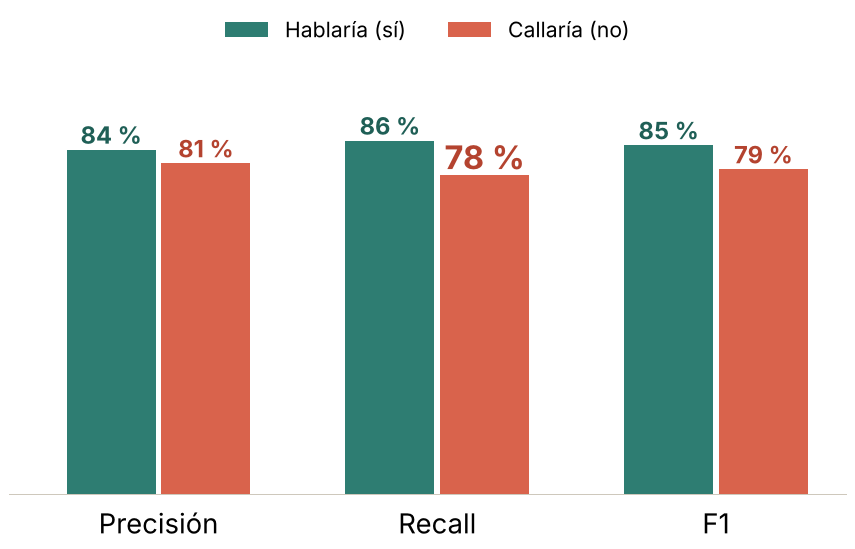

In [47]:
vp, fn = matriz_19[0]                                                                     # fila "Sí": verdaderos positivos y falsos negativos
fp, vn = matriz_19[1]                                                                     # fila "No": falsos positivos y verdaderos negativos
f1 = lambda p, r: 2 * p * r / (p + r)
pre_si, rec_si, pre_no, rec_no = vp / (vp + fp), vp / (vp + fn), vn / (vn + fn), vn / (vn + fp)
METRICAS = [("Precisión", pre_si, pre_no), ("Recall", rec_si, rec_no), ("F1", f1(pre_si, rec_si), f1(pre_no, rec_no))]
fig, ax = plt.subplots(figsize=(12, 6.4)); ancho = 0.34
for i, (nombre, si, no) in enumerate(METRICAS):
    ax.bar(i - ancho / 2, si, ancho * 0.94, color=VERDE); ax.bar(i + ancho / 2, no, ancho * 0.94, color=CORAL)
    ax.text(i - ancho / 2, si + 0.015, f"{si:.0%}".replace("%", " %"), ha="center", fontsize=19, color="#1F5F56", fontweight="bold")
    ax.text(i + ancho / 2, no + 0.015, f"{no:.0%}".replace("%", " %"), ha="center", fontsize=(26 if nombre == "Recall" else 19),
            color="#B4432F", fontweight="bold")
ax.set_xticks(range(3)); ax.set_xticklabels([m[0] for m in METRICAS], fontsize=22); ax.tick_params(axis="x", length=0, pad=10)
ax.set_ylim(0, 1.08); ax.set_yticks([]); ax.spines["left"].set_visible(False)
ax.bar([0], [0], color=VERDE, label="Hablaría (sí)"); ax.bar([0], [0], color=CORAL, label="Callaría (no)")
ax.legend(fontsize=17, frameon=False, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.12))
guardar_p(fig, "p_metricas_19.png")
plt.show()
print(f"VP {vp} · FN {fn} · FP {fp} · VN {vn} · accuracy {(vp + vn) / matriz_19.sum():.1%}")

### La curva de la destilación: cuántas preguntas hacen falta

La curva usa el orden del ranking (incluye preguntas de salud) y sirve para ver **cuántas** preguntas hacen falta. La estrella es **mi núcleo de 7**, entrenado en un modelo aparte, sin datos de salud.

Guardado: 04_figuras/p_curva_preguntas.png


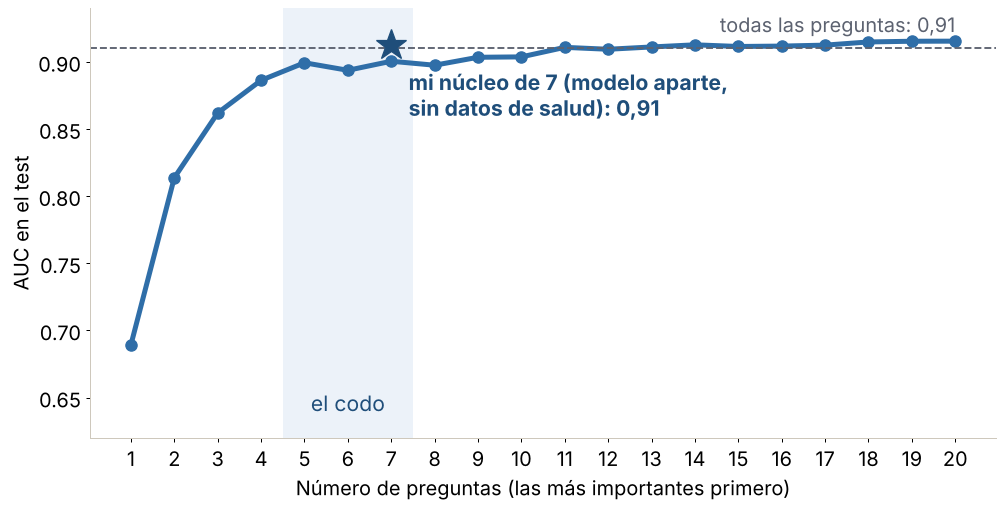

In [48]:
auc_nucleo = roc_auc_score(y_test_19 == "Sí", prob_nucleo)                               # AUC del modelo del núcleo de 7
fig, ax = plt.subplots(figsize=(13, 6.2))
ax.axvspan(4.5, 7.5, color="#D6E4F2", alpha=0.45, lw=0)                                  # zona del codo
ax.plot(curva.index, curva.values, color=AZUL, lw=4, marker="o", ms=9)                    # la curva
ax.axhline(auc_19, color=TINTA2, ls="--", lw=1.5)
ax.text(20, auc_19 + 0.012, f"todas las preguntas: {auc_19:.2f}".replace(".", ","), ha="right", fontsize=16, color=TINTA2)
ax.plot([7], [auc_nucleo], marker="*", ms=26, color="#1F4E7A", zorder=5)                  # la estrella: mi núcleo
ax.text(7.4, auc_nucleo - 0.053, f"mi núcleo de 7 (modelo aparte,\nsin datos de salud): {auc_nucleo:.2f}".replace(".", ","),
        fontsize=17, color="#1F4E7A", fontweight="bold")
ax.text(6, 0.64, "el codo", ha="center", fontsize=17, color="#1F4E7A")
ax.set_xticks(range(1, 21)); ax.set_xlabel("Número de preguntas (las más importantes primero)"); ax.set_ylabel("AUC en el test")
ax.set_ylim(0.62, 0.94)
guardar_p(fig, "p_curva_preguntas.png")
plt.show()

### Persona o empresa: qué temas usa cada modelo

Sumo la importancia de las preguntas por tema. Para **tener** un trastorno (33) pesa la salud personal; para **hablarlo** (19) pesan la empresa y el clima.

Guardado: 04_figuras/p_persona_empresa.png


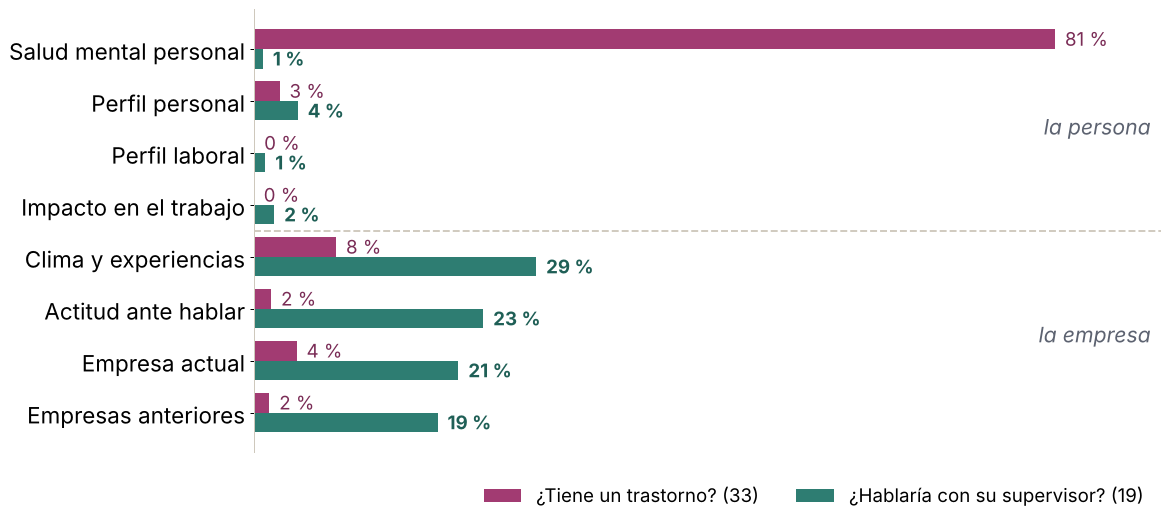

,33,19
F. Salud mental personal,81.3,0.9
A. Perfil personal,2.6,4.5
B. Perfil laboral,0.0,1.2
G. Impacto en el trabajo,0.0,2.1
H. Clima y experiencias,8.4,28.7
E. Disposición a hablar,1.8,23.3
C. Empresa actual,4.3,20.8
D. Empresas anteriores,1.6,18.6


In [49]:
def pct_por_tema(importancia):
    positiva = importancia.clip(lower=0)                                                   # quito las importancias negativas
    return (positiva / positiva.sum() * 100).groupby(tema_de).sum()                       # % por tema

TEMAS = pd.DataFrame({"33": pct_por_tema(importancia_33), "19": pct_por_tema(importancia_19)}).fillna(0)
NOMBRE_TEMA = {"A. Perfil personal": "Perfil personal", "B. Perfil laboral": "Perfil laboral", "C. Empresa actual": "Empresa actual",
               "D. Empresas anteriores": "Empresas anteriores", "E. Disposición a hablar": "Actitud ante hablar",
               "F. Salud mental personal": "Salud mental personal", "G. Impacto en el trabajo": "Impacto en el trabajo",
               "H. Clima y experiencias": "Clima y experiencias"}
ORDEN_T = ["F. Salud mental personal", "A. Perfil personal", "B. Perfil laboral", "G. Impacto en el trabajo",
           "H. Clima y experiencias", "E. Disposición a hablar", "C. Empresa actual", "D. Empresas anteriores"]
TEMAS = TEMAS.reindex(ORDEN_T).fillna(0)
fig, ax = plt.subplots(figsize=(13, 6.4)); y = np.arange(len(ORDEN_T)); h = 0.38
ax.barh(y - h / 2, TEMAS["33"], h, color=FRAMBUESA, label="¿Tiene un trastorno? (33)")
ax.barh(y + h / 2, TEMAS["19"], h, color=VERDE, label="¿Hablaría con su supervisor? (19)")
for yy, v in zip(y - h / 2, TEMAS["33"]): ax.text(v + 1, yy, f"{v:.0f} %", va="center", fontsize=15, color="#7A2C56")
for yy, v in zip(y + h / 2, TEMAS["19"]): ax.text(v + 1, yy, f"{v:.0f} %", va="center", fontsize=15, color="#1F5F56", fontweight="bold")
ax.set_yticks(y); ax.set_yticklabels([NOMBRE_TEMA[t] for t in ORDEN_T], fontsize=18); ax.invert_yaxis()
ax.set_xlim(0, 92); ax.set_xticks([]); ax.spines["bottom"].set_visible(False); ax.axhline(3.5, color=GRIS, lw=1.5, ls="--")
ax.text(91, 1.5, "la persona", ha="right", va="center", fontsize=17, color=TINTA2, style="italic")
ax.text(91, 5.5, "la empresa", ha="right", va="center", fontsize=17, color=TINTA2, style="italic")
ax.legend(loc="lower right", fontsize=15, frameon=False, bbox_to_anchor=(1, -0.16), ncol=2)
guardar_p(fig, "p_persona_empresa.png")
plt.show()
TEMAS.round(1)

### Un árbol de ejemplo

Para explicar cómo razona el Random Forest, entreno **un solo árbol pequeño** (3 niveles, mínimo 40 personas por hoja) con las mismas 612 personas de entrenamiento del modelo 19. El Random Forest hace 500 árboles más grandes y los hace votar. En cada rama, el árbol elige solo la pregunta que mejor separa a ese grupo.

Guardado: 04_figuras/p_arbol_ejemplo.png
Personas en las hojas: 612


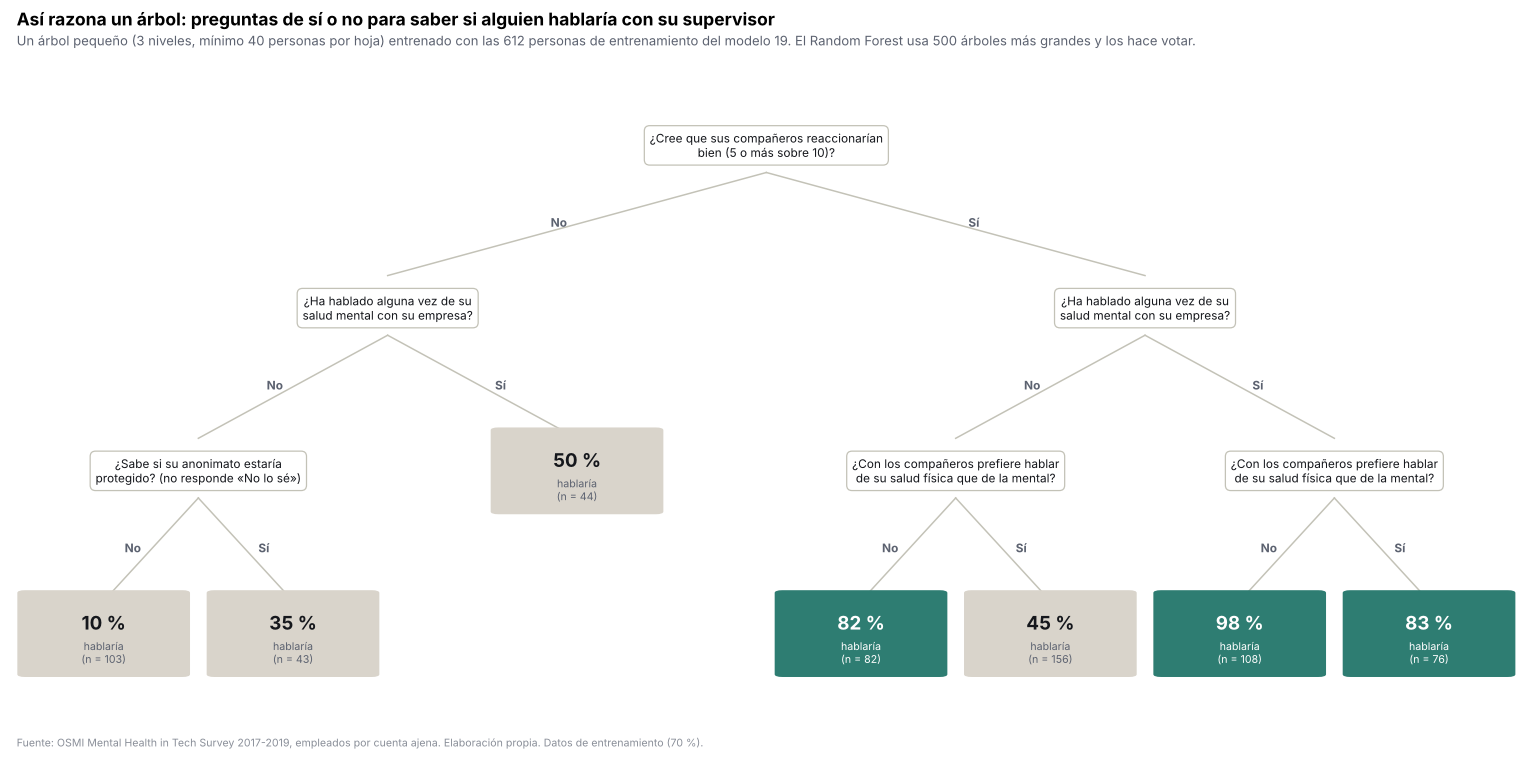

In [50]:
from sklearn.tree import DecisionTreeClassifier
from matplotlib.patches import FancyBboxPatch

arbol = DecisionTreeClassifier(max_depth=3, min_samples_leaf=40, random_state=SEMILLA).fit(X_train_19, y_train_19)
t = arbol.tree_; col_si = list(arbol.classes_).index("Sí")
TEXTO = {"p81_reaccion_companeros_0_10": "¿Cree que sus compañeros reaccionarían\nbien (5 o más sobre 10)?",
         "p58_hablo_con_empleador": "¿Ha hablado alguna vez de su\nsalud mental con su empresa?",
         "p11_anonimato_protegido__No lo sé": "¿Sabe si su anonimato estaría\nprotegido? (no responde «No lo sé»)",
         "p57_comodo_fisica_o_mental_companeros__Salud física": "¿Con los compañeros prefiere hablar\nde su salud física que de la mental?"}
INVERTIR = {"p11_anonimato_protegido__No lo sé"}                                          # aquí la rama derecha significa "No"

fig = plt.figure(figsize=(17, 8.2)); ax = fig.add_axes([0.005, 0.05, 0.99, 0.86])
ax.set_xlim(0, 1); ax.set_ylim(-0.12, 1.05); ax.axis("off")
def dibujar(nodo, x, y, ancho):
    n = t.n_node_samples[nodo]
    if t.children_left[nodo] == -1:                                                       # hoja: % que hablaría
        p = 100 * t.value[nodo][0][col_si] / t.value[nodo][0].sum()
        color = VERDE if p > 50 else "#D9D4CB"
        ax.add_patch(FancyBboxPatch((x - 0.052, y - 0.075), 0.104, 0.15, boxstyle="round,pad=0.005", fc=color, ec="none"))
        ax.text(x, y + 0.02, f"{p:.0f} %", ha="center", va="center", fontsize=15, fontweight="bold", color="white" if p > 50 else TINTA)
        ax.text(x, y - 0.035, f"hablaría\n(n = {n})", ha="center", va="center", fontsize=8.5, color="white" if p > 50 else TINTA2)
        return
    columna = X_train_19.columns[t.feature[nodo]]
    ax.text(x, y, TEXTO.get(columna, columna), ha="center", va="center", fontsize=9.5, color=TINTA,
            bbox=dict(boxstyle="round,pad=0.45", fc="white", ec="#c3c2b7"))
    izq, der = t.children_left[nodo], t.children_right[nodo]
    if columna in INVERTIR: izq, der = der, izq                                           # dibujo siempre el "No" a la izquierda
    for hijo, signo, etiqueta in [(izq, -1, "No"), (der, 1, "Sí")]:
        xh = x + signo * ancho / 2
        ax.plot([x, xh], [y - 0.05, y - 0.24], color="#c3c2b7", lw=1.2, zorder=0)
        ax.text((x + xh) / 2 + signo * 0.012, y - 0.15, etiqueta, ha="center", fontsize=9.5, color=TINTA2, fontweight="bold")
        dibujar(hijo, xh, y - 0.3, ancho / 2)
dibujar(0, 0.5, 0.92, 0.5)
fig.suptitle("Así razona un árbol: preguntas de sí o no para saber si alguien hablaría con su supervisor", x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.0)
fig.text(0.01, 0.95, "Un árbol pequeño (3 niveles, mínimo 40 personas por hoja) entrenado con las 612 personas de entrenamiento del modelo 19. "
         "El Random Forest usa 500 árboles más grandes y los hace votar.", fontsize=10.5, color=TINTA2)
fig.text(0.01, 0.0, "Fuente: OSMI Mental Health in Tech Survey 2017-2019, empleados por cuenta ajena. Elaboración propia. Datos de entrenamiento (70 %).", fontsize=8.5, color="#8A8F99")
guardar_p(fig, "p_arbol_ejemplo.png")
plt.show()
print("Personas en las hojas:", int(sum(t.n_node_samples[i] for i in range(t.node_count) if t.children_left[i] == -1)))

### Curva ROC del modelo 19 (para el anexo)

Guardado: 04_figuras/p_roc_19.png


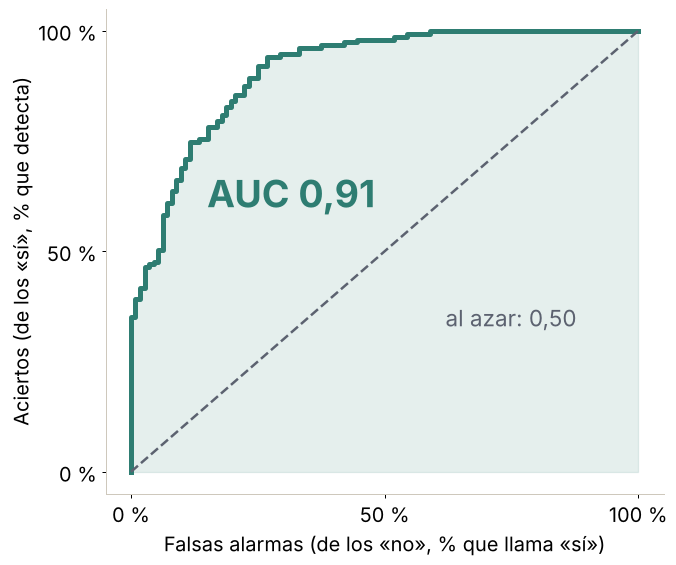

In [51]:
from sklearn.metrics import roc_curve
fpr_19, tpr_19, _ = roc_curve(y_test_19 == "Sí", prob_19)                                # aciertos y falsas alarmas para cada umbral
fig, ax = plt.subplots(figsize=(8, 7))
ax.fill_between(fpr_19, tpr_19, color=VERDE, alpha=0.12); ax.plot(fpr_19, tpr_19, color=VERDE, lw=4)
ax.plot([0, 1], [0, 1], ls="--", color=TINTA2, lw=2)
ax.text(0.15, 0.60, f"AUC {auc_19:.2f}".replace(".", ","), fontsize=30, fontweight="bold", color=VERDE)
ax.text(0.62, 0.33, "al azar: 0,50", fontsize=18, color=TINTA2)
ax.set_xlabel("Falsas alarmas (de los «no», % que llama «sí»)", fontsize=16); ax.set_ylabel("Aciertos (de los «sí», % que detecta)", fontsize=16)
ax.set_xticks([0, .5, 1]); ax.set_xticklabels(["0 %", "50 %", "100 %"]); ax.set_yticks([0, .5, 1]); ax.set_yticklabels(["0 %", "50 %", "100 %"])
guardar_p(fig, "p_roc_19.png")
plt.show()